# Complexity-03k — L'arbre couvrant de poids minimal en temps linéaire déterministe

> **Bandeau preprint.** Ce carnet travaille sur le rapport ECCC TR26-339, *A Deterministic Linear Time Algorithm for Minimum Spanning Tree*, de Sanjeev Khanna, Aaron Putterman et Junkai Song, daté du 23 novembre 2026. C'est un **preprint, non évalué par les pairs** au moment de la rédaction. Le carnet **ne démontre pas** son résultat : il mesure les objets que ce résultat met en jeu, et sépare à chaque section ce qui est **mesuré ici**, ce qui est **cité du texte** des auteurs, et ce qui reste **ouvert**.

| | |
|---|---|
| **Série** | `InformationCalcul/Complexity`, accrétion de **03** (k) |
| **Public** | Recherche (fin de licence / master) |
| **Technologies** | Python 3.13, matplotlib, bibliothèque standard seule |
| **Durée** | 90 min |

## Objectifs

1. Compter les **comparaisons de poids** — la seule ressource que le modèle autorise — et rien d'autre.
2. Mesurer les trois classiques (Kruskal, Prim, Borůvka) sur des graphes de tailles croissantes, et voir **quel** facteur chacune paie.
3. Calculer **exactement** la complexité de décision `T*(H)` d'un petit graphe, et la distinguer de la complexité d'un **algorithme**.
4. Calculer **exactement** `alpha(m,n)` et situer la borne historique `m * alpha(m,n)` face à la borne linéaire.
5. Mesurer les deux certificats qui font vivre l'algorithme : le filtre **F-lourde / F-légère**, et le lemme d'**échantillonnage** de Karger-Klein-Tarjan.
6. Assembler un jouet qui a la **silhouette** de l'algorithme du papier, et mesurer où son coût part.

## Prérequis

Arbres couvrants et cycles (propriété du cycle), tri fusion et sa récurrence, notation asymptotique, logarithme itéré. Aucune connaissance préalable de la fonction d'Ackermann : elle est construite ici.

**Navigation** : [README de la série](README.md) | [Version C#](Complexity-03k-KhannaPuttermanSong-ArbreCouvrantLineaireDeterministe-CSharp.ipynb) | [Carnet 03 de base](Complexity-03-HierarchieTemporelle-Python.ipynb)

***

## Ce que ce carnet mesure — et ce qu'il ne fait pas

Le résultat du preprint tient en une ligne : la complexité en **comparaisons** de l'arbre couvrant minimal est **linéaire**, `T*(m,n) = O(m)`, là où l'on savait `T*(m,n) = O(m alpha(m,n))` et `Omega(m)`. Par une réduction antérieure (Pettie-Ramachandran, JACM 2002), cela donne un **algorithme** déterministe en `O(m)`.

Ce carnet prend le résultat comme une **boîte noire citée** et mesure les objets qui le rendent intelligible :

| Section | Objet mesuré | Ce que la mesure peut montrer |
|---|---|---|
| 2 | pire cas exact du tri fusion | l'unité de coût, et le `m log m` que Kruskal doit payer |
| 3 | Kruskal, Prim, Borůvka comptés | quel facteur logarithmique chacune porte |
| 4 | `T*(H)` exact | la différence **décision** / **algorithme** |
| 5 | `alpha(m,n)` exact | que `m * alpha` vaut au plus `4m` sur toute entrée réaliste |
| 6 | filtre F-lourde / F-légère | ce qu'on peut jeter sans perdre l'arbre |
| 7 | lemme d'échantillonnage | pourquoi le filtre aléatoire tient en espérance |
| 8 | jouet Borůvka + échantillon + filtre | où le coût part dans une architecture concrète |

**Ce que ce carnet ne fait pas**, et qu'aucune de ses figures ne prouve : il ne démontre pas `T*(m,n) = O(m)`, il ne reproduit pas l'algorithme du preprint, il ne borne pas sa constante, et il ne dit rien de la validité du preprint, qui n'est pas évalué par les pairs.

Trois statuts sont employés partout dans la suite :

- **MESURÉ** — un nombre produit par une cellule de ce carnet, sur cette machine.
- **CITÉ** — une phrase du texte des auteurs, recopiée et attribuée.
- **OUVERT** — une question que rien ici ne tranche.


In [1]:
import itertools
import math
import random
import sys
import time
from collections import Counter
from collections.abc import Callable

import matplotlib
import matplotlib.pyplot as plt

# Les sections 4 et 8 descendent une recursion profonde : on releve la limite par defaut.
sys.setrecursionlimit(100000)

print("Imports OK :", sys.version.split()[0], "--", matplotlib.__version__)


Imports OK : 3.13.16 -- 3.11.0


## 1. Le modèle de coût : comparer, et rien d'autre

Le preprint se place dans le modèle le plus pauvre possible. **CITÉ** :

> We study the most general version of the problem, where the algorithm may only compare edge weights in pairs, with each comparison taking constant time, and otherwise treats the weights as opaque keys (thus, the algorithm works for even the most unstructured weighted settings).
>
> — TR26-339, §1

Conséquence opérationnelle : un poids n'est jamais lu, jamais additionné, jamais arrondi. La seule instruction autorisée sur deux poids est « le premier est-il strictement plus petit que le second ? ». Tout ce qui suit compte donc **une seule chose** : le nombre d'appels à cette comparaison.

C'est ce qui rend les poids entiers de `1` à `m` légitimes pour toutes les expériences de ce carnet : le modèle ne voit que leur **ordre**, et un tirage aléatoire de cet ordre est exactement une instance du problème. Les poids distincts évitent en plus les ex aequo, que la définition de `T*` exclut elle aussi (section 4).

L'instrument est une classe de trois lignes, `Comparaisons`. Chaque algorithme reçoit une instance et ne touche aux poids qu'à travers elle : c'est la règle du jeu, pas une commodité de mesure.


## 2. L'instrument : un tri fusion dont le pire cas est exact

Pourquoi commencer par un tri ? Parce que les trois classiques de la section 3 en contiennent un, explicitement ou non : Kruskal trie ses arêtes, Prim maintient un tas, Borůvka trie implicitement à chaque phase. Le coût de comparaison d'un tri est donc l'étalon de tout le reste, et il vaut mieux le connaître exactement que de le majorer.

Le tri fusion descendant coupe une liste de `n` éléments en deux, trie chaque moitié, puis fusionne. Fusionner deux listes de tailles totales `n` demande au plus `n - 1` comparaisons, et ce maximum est atteint. D'où la récurrence, avec `C(0) = C(1) = 0` :

```
C(n) = C(floor(n/2)) + C(n - floor(n/2)) + (n - 1)
```

Sa solution est connue et close : avec `k = ceil(log2 n)`,

```
C(n) = n * k - 2**k + 1
```

La cellule suivante vérifie cette forme de trois façons indépendantes : par **force brute** sur toutes les permutations jusqu'à `n = 8`, par la **récurrence** jusqu'à `n = 400`, et par une **identité marginale** — le coût du `n`-ième élément vaut exactement `ceil(log2 n)` — jusqu'à `n = 2000`. Trois vérifications, parce qu'une seule forme close vérifiée sur ses propres valeurs ne prouve rien.


In [2]:
class Comparaisons:
    """L'instrument : un algorithme ne touche aux poids que par inferieur(a, b)."""

    def __init__(self) -> None:
        self.n = 0

    def inferieur(self, a: float, b: float) -> bool:
        self.n += 1
        return a < b


def tri_fusion(items: list[int], w: list[float], cmp: Comparaisons) -> list[int]:
    """Tri fusion descendant, instrumente."""
    if len(items) <= 1:
        return list(items)
    milieu = len(items) // 2
    gauche = tri_fusion(items[:milieu], w, cmp)
    droite = tri_fusion(items[milieu:], w, cmp)
    fusion: list[int] = []
    i = j = 0
    while i < len(gauche) and j < len(droite):
        if cmp.inferieur(w[gauche[i]], w[droite[j]]):
            fusion.append(gauche[i])
            i += 1
        else:
            fusion.append(droite[j])
            j += 1
    fusion.extend(gauche[i:])
    fusion.extend(droite[j:])
    return fusion


def forme_close(n: int) -> int:
    """Pire cas exact du tri fusion descendant : C(n) = C(n//2) + C(n - n//2) + n - 1."""
    if n <= 1:
        return 0
    k = (n - 1).bit_length()
    return n * k - (1 << k) + 1


print("Pire cas du tri fusion, max sur toutes les permutations :")
for n in range(1, 9):
    pire = 0
    for perm in itertools.permutations(range(n)):
        c = Comparaisons()
        tri_fusion(list(range(n)), list(perm), c)
        pire = max(pire, c.n)
    assert pire == forme_close(n), (n, pire, forme_close(n))
    print(f"   n={n}  max mesure={pire:>2d}  forme close={forme_close(n):>2d}")
for n in range(9, 401):
    assert forme_close(n) == forme_close(n // 2) + forme_close(n - n // 2) + n - 1
print("   recurrence <-> forme close verifiee sur n = 9..400")
for n in range(1, 2001):
    assert forme_close(n) - forme_close(n - 1) == (n - 1).bit_length()
print("   cout marginal C(n) - C(n-1) = ceil(log2 n), verifie sur n = 1..2000")
print("   couts marginaux pour n = 1..16 :",
      " ".join(str(forme_close(n) - forme_close(n - 1)) for n in range(1, 17)))
print()
print(f"   {'n':>8s} {'C(n)':>9s} {'C(n)/n':>8s} {'log2 n':>8s}")
for k in range(1, 12):
    n = 2 ** k
    print(f"   {n:>8d} {forme_close(n):>9d} {forme_close(n) / n:>8.3f} {k:>8d}")
print(f"   C(1000) = {forme_close(1000)} : pire cas exact du tri de 1000 elements.")


Pire cas du tri fusion, max sur toutes les permutations :
   n=1  max mesure= 0  forme close= 0
   n=2  max mesure= 1  forme close= 1
   n=3  max mesure= 3  forme close= 3
   n=4  max mesure= 5  forme close= 5
   n=5  max mesure= 8  forme close= 8
   n=6  max mesure=11  forme close=11
   n=7  max mesure=14  forme close=14


   n=8  max mesure=17  forme close=17
   recurrence <-> forme close verifiee sur n = 9..400
   cout marginal C(n) - C(n-1) = ceil(log2 n), verifie sur n = 1..2000
   couts marginaux pour n = 1..16 : 0 1 2 2 3 3 3 3 4 4 4 4 4 4 4 4

          n      C(n)   C(n)/n   log2 n
          2         1    0.500        1
          4         5    1.250        2
          8        17    2.125        3
         16        49    3.062        4
         32       129    4.031        5
         64       321    5.016        6
        128       769    6.008        7
        256      1793    7.004        8
        512      4097    8.002        9
       1024      9217    9.001       10
       2048     20481   10.000       11
   C(1000) = 8977 : pire cas exact du tri de 1000 elements.


### Lecture du résultat

Les trois vérifications passent, et elles disent trois choses différentes.

**La force brute** (lignes `n=1..8`) compare le maximum mesuré sur *toutes* les permutations à la forme close : `0, 1, 3, 5, 8, 11, 14, 17`. C'est une égalité exhaustive jusqu'à `n = 8`, pas un échantillon.

**La récurrence** (ligne `9..400`) montre que la forme close satisfait bien la récurrence qu'elle prétend résoudre — utile, parce qu'une erreur d'arrondi sur `n` impair se verrait là et nulle part ailleurs.

**L'identité marginale** est la plus parlante : `C(n) - C(n-1) = ceil(log2 n)`, vérifié sur `n = 1..2000`. Ajouter le `n`-ième élément coûte exactement `ceil(log2 n)` comparaisons, quels que soient les poids. La suite des coûts marginaux pour `n = 1..16` le montre à l'œil :

```
0  1  2  2  3  3  3  3  4  4  4  4  4  4  4  4
```

Chaque palier dure deux fois plus longtemps que le précédent : c'est la signature d'un logarithme. Et ce logarithme n'est pas une maladresse du tri fusion — aucun tri par comparaison ne peut faire mieux, dans le pire cas, que `ceil(log2(n!))` comparaisons (un arbre de décision binaire de profondeur `d` a au plus `2**d` feuilles, et il faut une feuille par permutation).

Pour `n = 2**k`, la table donne `C(n)/n = k - 1 + 1/n`, c'est-à-dire

```
C(n) = n * log2(n) - n + 1          (n puissance de deux)
```

soit exactement **une comparaison par élément de moins** que la borne `n log2 n` qu'on cite souvent. Pour `n = 1000`, la forme close donne `C(1000) = 8977`, à comparer aux `9966` de `n log2 n`.

**MESURÉ, et c'est le point à retenir pour la section 7** : `8977` est un maximum sur les permutations, pas le coût d'une entrée particulière. Un tri donné peut coûter beaucoup moins — la section 7 en mesurera deux, à `8694` et `4932` comparaisons pour 1000 poids. Mais un algorithme déterministe qui doit trier **quelle que soit l'entrée** paie `Theta(m log m)` dans le pire cas : c'est précisément ce que la borne linéaire du preprint doit éviter de payer.

La figure suivante montre les deux suites superposées : le coût marginal mesuré, et `log2(n)`.


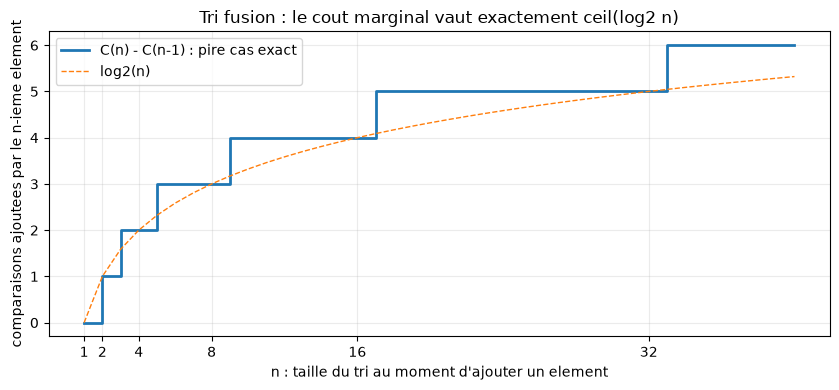

In [3]:
n_max = 40
marginal = [forme_close(n) - forme_close(n - 1) for n in range(1, n_max + 1)]
fig, ax = plt.subplots(figsize=(8.5, 4.0))
ax.step(range(1, n_max + 1), marginal, where="post", linewidth=2.0,
        label="C(n) - C(n-1) : pire cas exact")
ax.plot(range(1, n_max + 1), [math.log2(n) for n in range(1, n_max + 1)],
        linestyle="--", linewidth=1.0, label="log2(n)")
ax.set_xticks([1, 2, 4, 8, 16, 32])
ax.set_xlabel("n : taille du tri au moment d'ajouter un element")
ax.set_ylabel("comparaisons ajoutees par le n-ieme element")
ax.set_title("Tri fusion : le cout marginal vaut exactement ceil(log2 n)")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


### Lecture de la figure

L'escalier et la courbe en pointillés se touchent : le coût marginal est le logarithme, au plafond près. Les marches sont larges d'un facteur deux, ce qui est exactement la structure d'un arbre de fusion — chaque niveau de l'arbre double le nombre de sous-listes, donc la profondeur augmente d'une unité tous les doubles.

Trois conséquences pour la suite :

1. Un tri coûte `n log2 n` **au niveau de l'élément**, mais chaque élément ne paie le logarithme qu'autant qu'il participe à des fusions de listes de plus en plus grandes.
2. Le coût est **déterministe** : il ne dépend que de `n`, jamais des valeurs. C'est pour cela que `C(n)` peut servir d'étalon.
3. Le pire cas est atteint, mais pas par une entrée privilégiée. C'est une différence de nature avec la borne `T*(H)` de la section 4, qui est un **minimum** sur les arbres de décision — donc une borne atteignable par un algorithme bien choisi.

La section suivante met ce tri au travail : Kruskal en contient un, et c'est là que le facteur `log` entre dans le coût des classiques.


## 3. Trois classiques, comptés

Les trois algorithmes historiques sont tous **gloutons** et tous corrects : ils rendent le même arbre. Ce qui les distingue n'est donc pas le résultat, mais **où partent les comparaisons**. Le preprint les décrit lui-même, **CITÉ** (§1.1) :

> In 1930, Jarník described a tree-growing alternative. Indeed, this work proposed starting from a single vertex and repeatedly adding the cheapest edge leaving the current tree. This algorithm was later rediscovered by Prim and by Dijkstra and is now commonly called Prim's algorithm. Kruskal developed yet another alternative. In his work, he proposes scanning the edges in increasing order of weight and keeping each edge that closes no cycle.

et pour Borůvka :

> each vertex selects its incident edge with the smallest weight. The algorithm then commits to keeping these edges in the MST, and effectively contracts on these committed edges, treating the created components as their own vertices. In this way, every phase at least halves the number of vertices, so after O(log n) phases, each using O(m) comparisons, one obtains an MST.

Le preprint résume aussi le coût de chacun, **CITÉ** (§1.1) :

> Kruskal's algorithm sorts the edges in O(m log m) = O(m log n) time, Prim's algorithm performs O(m) operations on a binary heap of at most n vertices, and Borůvka's algorithm may need Θ(log n) linear-time phases.

Trois implémentations suivent, toutes écrites à la main et instrumentées de la même façon :

- **Kruskal** : tri de toutes les arêtes, puis un Union-Find qui accepte une arête si elle relie deux composantes distinctes.
- **Prim** : un tas binaire de **clés = arêtes**, alimenté par les voisinages ; on retire le minimum, on l'ajoute si son extrémité est neuve.
- **Borůvka** : à chaque phase, chaque composante retient son arête sortante la plus légère ; les composantes fusionnent, on recommence. Les arêtes internes sont retirées avant la phase suivante.

Le Union-Find compte aussi ses propres pas de boucle (`appels`, `pas`), ce qui servira en section 5. Les poids sont des entiers distincts tirés au hasard : le graphe ne sait rien de son ordre, et le modèle de comparaison ne voit que cet ordre.

La cellule de mesure vérifie que les trois rendent le même arbre : par `assert`, la liste triée des poids de Prim et celle de Borůvka sont égales à celle de Kruskal. Cela entraîne l'égalité des poids totaux ; comme Kruskal rend un arbre minimal, les deux autres aussi, et des poids distincts le rendent unique.


In [4]:
class UnionFind:
    """Union-Find, compression de chemin par fractionnement ; compte ses pas de boucle."""

    def __init__(self, n: int) -> None:
        self.parent = list(range(n))
        self.appels = 0
        self.pas = 0

    def copie(self) -> "UnionFind":
        u = UnionFind(0)
        u.parent = list(self.parent)
        return u

    def trouver(self, x: int) -> int:
        p = self.parent
        self.appels += 1
        while p[x] != x:
            p[x] = p[p[x]]
            x = p[x]
            self.pas += 1
        return x

    def unir(self, a: int, b: int) -> bool:
        ra, rb = self.trouver(a), self.trouver(b)
        if ra == rb:
            return False
        self.parent[ra] = rb
        return True


def graphe_aleatoire(n: int, ratio: float, graine: int) -> tuple[list[tuple[int, int]], list[float]]:
    """n sommets, environ ratio*n aretes, poids distincts melanges : le graphe ne sait rien de son ordre."""
    rng = random.Random(graine)
    aretes: list[tuple[int, int]] = []
    vues: set[tuple[int, int]] = set()
    for v in range(1, n):
        u = rng.randrange(v)
        aretes.append((u, v))
        vues.add((u, v))
    objectif = min(int(ratio * n), n * (n - 1) // 2)
    while len(aretes) < objectif:
        u, v = rng.randrange(n), rng.randrange(n)
        if u == v:
            continue
        cle = (min(u, v), max(u, v))
        if cle in vues:
            continue
        vues.add(cle)
        aretes.append(cle)
    w: list[float] = [0.0] * len(aretes)
    ordre = list(range(len(aretes)))
    rng.shuffle(ordre)
    for k, e in enumerate(ordre):
        w[e] = float(k + 1)
    return aretes, w


def kruskal(E: list[int], aretes: list[tuple[int, int]], w: list[float], cmp: Comparaisons,
            uf: UnionFind) -> list[int]:
    arbre: list[int] = []
    for e in tri_fusion(E, w, cmp):
        u, v = aretes[e]
        if uf.unir(u, v):
            arbre.append(e)
    return arbre


def prim(n: int, aretes: list[tuple[int, int]], w: list[float], cmp: Comparaisons) -> list[int]:
    """Prim, tas binaire ecrit a la main ; les cles sont les aretes (poids distincts : 1 comparaison)."""
    adj: list[list[tuple[int, int]]] = [[] for _ in range(n)]
    for e, (u, v) in enumerate(aretes):
        adj[u].append((e, v))
        adj[v].append((e, u))
    tas: list[int] = []

    def moins(e1: int, e2: int) -> bool:
        return cmp.inferieur(w[e1], w[e2])

    def pousser(e: int) -> None:
        tas.append(e)
        i = len(tas) - 1
        while i > 0:
            p = (i - 1) // 2
            if moins(tas[i], tas[p]):
                tas[i], tas[p] = tas[p], tas[i]
                i = p
            else:
                break

    def retirer() -> int:
        tete = tas[0]
        dernier = tas.pop()
        if tas:
            tas[0] = dernier
            i = 0
            while True:
                g, d = 2 * i + 1, 2 * i + 2
                s = i
                if g < len(tas) and moins(tas[g], tas[s]):
                    s = g
                if d < len(tas) and moins(tas[d], tas[s]):
                    s = d
                if s == i:
                    break
                tas[i], tas[s] = tas[s], tas[i]
                i = s
        return tete

    vu = [False] * n
    arbre: list[int] = []
    vu[0] = True
    for e, _ in adj[0]:
        pousser(e)
    while tas:
        e = retirer()
        u, v = aretes[e]
        if vu[u] and vu[v]:
            continue
        arbre.append(e)
        x = v if vu[u] else u
        vu[x] = True
        for f, y in adj[x]:
            if not vu[y]:
                pousser(f)
    return arbre


def phase_boruvka(E: list[int], aretes: list[tuple[int, int]], w: list[float], cmp: Comparaisons,
                  uf: UnionFind) -> list[int]:
    """Chaque composante garde son arete sortante la plus legere : elle est dans l'arbre."""
    meilleure: dict[int, int] = {}
    for e in E:
        u, v = aretes[e]
        ru, rv = uf.trouver(u), uf.trouver(v)
        if ru == rv:
            continue
        for r in (ru, rv):
            if r not in meilleure:
                meilleure[r] = e
            elif cmp.inferieur(w[e], w[meilleure[r]]):
                meilleure[r] = e
    ajoutees: list[int] = []
    for e in meilleure.values():
        u, v = aretes[e]
        if uf.unir(u, v):
            ajoutees.append(e)
    return ajoutees


def boruvka(E: list[int], aretes: list[tuple[int, int]], w: list[float], cmp: Comparaisons,
            uf: UnionFind) -> tuple[list[int], int]:
    """Renvoie (aretes de l'arbre, nombre de phases) : chaque phase au moins divise les composantes par 2."""
    arbre: list[int] = []
    phases = 0
    while True:
        ajoutees = phase_boruvka(E, aretes, w, cmp, uf)
        if not ajoutees:
            return arbre, phases
        phases += 1
        arbre.extend(ajoutees)
        E = [e for e in E if uf.trouver(aretes[e][0]) != uf.trouver(aretes[e][1])]


Les trois algorithmes et le générateur de graphes sont en place. La cellule suivante les fait tourner sur six tailles, de 500 à 16 000 sommets, à densité fixée `m = 3n`, et rapporte les comparaisons **par arête** — une unité qui rend les tailles comparables.


In [5]:
print("Comparaisons de poids par arete, densite m = 3n :")
print(f"   {'n':>6s} {'m':>7s} {'Kruskal':>8s} {'Prim':>8s} {'Boruvka':>8s} {'phases':>7s} {'log2 n':>7s} {'s':>6s}")
lignes = []
for n in [500, 1000, 2000, 4000, 8000, 16000]:
    aretes, w = graphe_aleatoire(n, 3.0, graine=n)
    m = len(aretes)
    t0 = time.time()
    cmp_k = Comparaisons()
    ref = sorted(w[e] for e in kruskal(list(range(m)), aretes, w, cmp_k, UnionFind(n)))
    cmp_p = Comparaisons()
    arbre_p = prim(n, aretes, w, cmp_p)
    assert sorted(w[e] for e in arbre_p) == ref, "Prim ne rend pas l'arbre de Kruskal"
    cmp_b = Comparaisons()
    arbre_b, phases_b = boruvka(list(range(m)), aretes, w, cmp_b, UnionFind(n))
    assert sorted(w[e] for e in arbre_b) == ref, "Boruvka ne rend pas l'arbre de Kruskal"
    t1 = time.time()
    lignes.append((n, m, cmp_k.n / m, cmp_p.n / m, cmp_b.n / m, phases_b))
    print(f"   {n:>6d} {m:>7d} {cmp_k.n / m:>8.2f} {cmp_p.n / m:>8.2f} {cmp_b.n / m:>8.2f}"
          f" {phases_b:>7d} {math.log2(n):>7.1f} {t1 - t0:>6.1f}")
print()
print("   gain par doublement de n :")
for i in range(1, len(lignes)):
    print(f"   n {lignes[i - 1][0]:>6d} -> {lignes[i][0]:>6d} : Kruskal"
          f" {lignes[i][2] - lignes[i - 1][2]:+.2f}   Prim {lignes[i][3] - lignes[i - 1][3]:+.2f}"
          f"   Boruvka {lignes[i][4] - lignes[i - 1][4]:+.2f}")
print("   controle : les trois methodes rendent le meme arbre (memes poids, verifie par assert).")


Comparaisons de poids par arete, densite m = 3n :
        n       m  Kruskal     Prim  Boruvka  phases  log2 n      s
      500    1500     9.29    18.84     5.22       4     9.0    0.0
     1000    3000    10.31    21.09     6.07       5    10.0    0.0
     2000    6000    11.30    23.19     6.26       5    11.0    0.1


     4000   12000    12.30    25.44     6.66       5    12.0    0.2


     8000   24000    13.31    27.62     7.14       6    13.0    0.5


    16000   48000    14.30    29.87     7.91       6    14.0    1.3

   gain par doublement de n :
   n    500 ->   1000 : Kruskal +1.01   Prim +2.24   Boruvka +0.85
   n   1000 ->   2000 : Kruskal +0.99   Prim +2.11   Boruvka +0.19
   n   2000 ->   4000 : Kruskal +1.00   Prim +2.25   Boruvka +0.40
   n   4000 ->   8000 : Kruskal +1.01   Prim +2.17   Boruvka +0.48
   n   8000 ->  16000 : Kruskal +1.00   Prim +2.25   Boruvka +0.77
   controle : les trois methodes rendent le meme arbre (memes poids, verifie par assert).


### Lecture du résultat

Les trois `assert` passent : Prim et Borůvka rendent l'arbre de Kruskal sur les six tailles. Les colonnes se lisent en **comparaisons par arête**, donc le total s'obtient en multipliant par `m`.

**Kruskal : `+1,00` par doublement.** C'est le coût du tri, et rien d'autre : le Union-Find ne fait aucune comparaison de poids. Les gains `+1,01, +0,99, +1,00, +1,01, +1,00` sont exactement le `+1` que prend `log2 n` quand `n` double. Quant au niveau (`9,29` à `14,30` par arête), il reste **sous** le pire cas exact de la section 2 : `C(1500) = 14453` et `C(48000) = 702465`, soit `9,64` et `14,63` par arête. La permutation aléatoire n'atteint pas le pire cas, on l'avait annoncé.

**Prim : environ `+2,2` par doublement.** Chaque arête entre une fois dans le tas et en sort une fois, et chaque opération au tas parcourt un chemin de profondeur logarithmique en comparant jusqu'à deux enfants par niveau. D'où un coefficient voisin de `2` devant `log2 n` : `18,84` pour `log2 n = 9`, `29,87` pour `log2 n = 14`. Prim est le plus coûteux des trois **en comparaisons**, sur des graphes de densité 3 — ce qui ne dit rien de son temps de calcul réel, que ce carnet ne mesure pas.

**Borůvka : le plus bas, et le plus plat.** De `5,22` à `7,91` comparaisons par arête, pour des gains de `+0,19` à `+0,85` par doublement : la croissance est bien plus lente que logarithmique sur cette plage. La colonne `phases` explique pourquoi : il y a `4` à `6` phases, alors que `log2 n` vaut `9` à `14`. La borne « every phase at least halves the number of vertices » du preprint est une borne **supérieure** ; la trace de la section 8 montrera que, sur un graphe aléatoire de `4000` sommets, une seule phase ramène le nombre de composantes à `1020`. En moyenne, une phase coûte ici entre `1,19` et `1,33` comparaison par arête : c'est le rapport des colonnes `Boruvka` et `phases`, ligne par ligne (le minimum, `7,14 / 6`, vaut `1,19` ; le maximum, `6,66 / 5`, vaut `1,33`).

**Ce que la table ne prouve pas.** Borůvka est le moins coûteux sur ces six tailles, mais son coût **croît** (`5,22 → 7,91`) et le preprint le donne `O(m log n)` au pire : la ligne ne suffit pas à distinguer `m log log n` de `m alpha(m,n)`, ni l'un ni l'autre de `m`. Trancher demanderait des tailles inaccessibles ici ; c'est tout l'objet des sections 4 et 5.

Les timings de la dernière colonne ne sont qu'indicatifs : ils varient d'une machine à l'autre, alors que les comparaisons, elles, sont reproductibles au bit près.


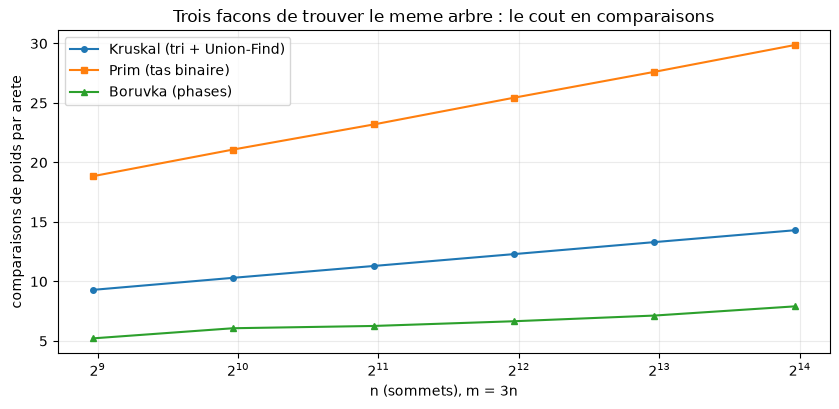

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
xs = [r[0] for r in lignes]
for etiquette, indice, style in [("Kruskal (tri + Union-Find)", 2, "o-"),
                                 ("Prim (tas binaire)", 3, "s-"),
                                 ("Boruvka (phases)", 4, "^-")]:
    ax.plot(xs, [r[indice] for r in lignes], style, label=etiquette, markersize=4)
ax.set_xscale("log", base=2)
ax.set_xlabel("n (sommets), m = 3n")
ax.set_ylabel("comparaisons de poids par arete")
ax.set_title("Trois facons de trouver le meme arbre : le cout en comparaisons")
ax.legend()
ax.grid(alpha=0.25, which="both")
fig.tight_layout()
plt.show()


### Lecture de la figure

L'axe des abscisses est `log2 n` : une droite de pente `s` y signifie un coût par arête de la forme `s * log2 n + c`.

- **Kruskal** est une droite de pente `1` sur toute la plage : `m log m`, le prix du tri.
- **Prim** est une droite de pente voisine de `2,2` : environ deux opérations au tas par arête, chacune logarithmique.
- **Borůvka** est nettement plus plat, et sa pente **diminue** : la courbe s'aplatit à mesure que `n` grandit. C'est le comportement attendu d'un algorithme dont les phases se raccourcissent quand le graphe grandit, mais rien ici ne démontre qu'elle resterait plate indéfiniment.

L'écart entre les trois courbes est l'espace où se joue la question du preprint : pour passer de `O(m log n)` à `O(m)`, il faut gagner un facteur qui n'est pas visible sur une plage de cinq doublements. C'est pourquoi la suite change d'échelle et d'objet : la section 4 regarde des graphes de **six arêtes** et calcule une quantité exacte, plutôt que d'extrapoler une courbe.


## 4. La complexité de décision : T*(H)

Les trois algorithmes de la section 3 sont des programmes. Le preprint, lui, commence par une question plus petite et plus précise : **combien de comparaisons faut-il, au minimum, pour trouver l'arbre ?** Le texte des auteurs pose l'objet ainsi :

> « let us fix a simple undirected graph H. A comparison tree for H is a decision tree where each internal node compares two edge weights and whose leaves are labeled with spanning forests of H. We say that it is correct if, for every possible assignment of distinct weights to H, the leaf reached is labeled with the resulting MSF. The depth of the comparison tree is then exactly the worst-case number of comparisons required to find an MSF of H. With this, we can define »

puis la définition elle-même, recomposée : dans le PDF l'astérisque est un exposant, et `H` et `T` sont des indices placés sous `max` et sous `min`, que l'extraction du texte déplace en fin de ligne.

`T*(m, n) = max_H min_T depth(T)`

> « where H ranges over all simple undirected graphs with m edges and n vertices, including disconnected ones, and T ranges over all correct comparison trees for H. »

Deux précisions du texte méritent d'être gardées :

- **Pourquoi les graphes non connexes entrent dans le maximum.** Une note de bas de page des auteurs l'explique : un graphe connexe à `m = n - 1` arêtes est son propre arbre couvrant, donc `T*(n-1, n) = 0` si on ne regardait que les graphes connexes, alors que **lire** une telle entrée coûte déjà `Omega(n)`. La définition inclut les graphes non connexes pour que le coût de lecture ne disparaisse pas du problème.
- **Décision d'abord, algorithme ensuite.** Le preprint borne `T*(m, n)`, c'est-à-dire le **nombre de comparaisons**, pas directement le temps d'exécution. Le passage de l'un à l'autre est un théorème antérieur, que les auteurs citent explicitement : « Pettie and Ramachandran gave a uniform pointer-machine algorithm that matches this bound. Indeed, on connected inputs, their algorithm runs in `O(T ∗(m, n))` time ». C'est ce que veut dire la phrase du résumé : borner la complexité de comparaison, puis « a known reduction of Pettie and Ramachandran (JACM 2002) immediately implies a linear time algorithm ». Un arbre de décision optimal n'est pas un programme ; c'est la réduction qui en fabrique un.

### Ce que la cellule suivante calcule exactement

`T*(m, n)` est un maximum sur **toutes** les topologies à `m` arêtes et `n` sommets : hors d'atteinte par le calcul direct. Ce qui est calculable exactement, c'est le **terme intérieur** : pour une topologie `H` fixée, la profondeur du meilleur arbre de comparaison, par minimax mémoïsé.

- Un état est un **ordre partiel** sur les arêtes, représenté par un ensemble de relations « `a` est plus légère que `b` » et sa clôture transitive.
- Un nœud interne choisit une paire d'arêtes non encore comparées, et le coût est `1 + max(les deux branches)`.
- Une feuille est atteinte quand **toutes** les permutations encore compatibles avec l'ordre partiel donnent le **même** arbre couvrant minimal : plus aucune comparaison ne peut rien changer.

Le calcul porte sur neuf topologies de six arêtes au plus, dont les permutations se laissent énumérer (`6! = 720` au plus). C'est une mesure exacte sur de très petits graphes ; ce n'est pas `T*(m, n)`.


In [7]:
def msf_d_un_ordre(aretes: list[tuple[int, int]], ordre: tuple[int, ...], n: int) -> tuple[int, ...]:
    uf = UnionFind(n)
    F: list[int] = []
    for e in ordre:
        u, v = aretes[e]
        if uf.unir(u, v):
            F.append(e)
    return tuple(sorted(F))


def t_etoile(aretes: list[tuple[int, int]], n: int) -> tuple[int, int, int, float]:
    """T*(H) : profondeur de l'arbre de comparaison optimal, par minimax memoise sur les ordres."""
    m = len(aretes)
    ordres = list(itertools.permutations(range(m)))
    rang = [{e: k for k, e in enumerate(o)} for o in ordres]
    msf = [msf_d_un_ordre(aretes, o, n) for o in ordres]
    memo: dict[tuple[int, ...], int] = {}

    def ajouter(lt: tuple[int, ...], a: int, b: int
                ) -> tuple[tuple[int, ...], list[tuple[int, int]]] | None:
        """Ajoute « a plus légère que b », ferme, et rend les relations nouvelles.

        `lt[y]` est l'ensemble des arêtes connues plus légères que `y`, tenu
        transitivement clos. Ajouter `a < b` oblige à ajouter aussi `x < y`
        pour tout `x` du bas de `a` et tout `y` du haut de `b` : le bas de `a`
        est `lt[a]` augmenté de `a`, et le haut de `b` se remonte en suivant
        les relations dans l'autre sens. Se tromper de sens ici ne casse rien
        visiblement : la fermeture déduit des relations que rien n'implique,
        l'arbre conclut trop tôt, et `T*` est sous-estimé.
        """
        if (lt[a] >> b) & 1:                   # b < a est déjà connu : contradiction
            return None
        bas = lt[a] | (1 << a)                 # {a}, et tout ce qui est plus léger que a
        haut = 1 << b                          # {b}, et tout ce qui est plus lourd que b
        frontiere = haut
        while frontiere:
            nouveau = 0
            for x in range(m):
                if (frontiere >> x) & 1:
                    for y in range(m):
                        if (lt[y] >> x) & 1:
                            nouveau |= 1 << y
            nouveau &= ~haut
            haut |= nouveau
            frontiere = nouveau
        if (haut >> a) & 1:                    # a est au-dessus de b : contradiction
            return None
        lt2 = list(lt)
        nouvelles: list[tuple[int, int]] = []
        for y in range(m):
            if (haut >> y) & 1:
                nouveau = bas & ~lt2[y]
                if nouveau:
                    for x in range(m):
                        if (nouveau >> x) & 1:
                            nouvelles.append((x, y))
                    lt2[y] |= bas
        return tuple(lt2), nouvelles

    def valeur(lt: tuple[int, ...], extensions: list[int]) -> int:
        if lt in memo:
            return memo[lt]
        if len({msf[i] for i in extensions}) == 1:
            memo[lt] = 0
            return 0
        meilleure = 10 ** 9
        for a in range(m):
            for b in range(a + 1, m):
                if (lt[a] >> b) & 1 or (lt[b] >> a) & 1:
                    continue
                r = ajouter(lt, a, b)
                if r is None:
                    continue
                lt1, paires1 = r
                v1 = valeur(lt1, [i for i in extensions
                                  if all(rang[i][x] < rang[i][y] for x, y in paires1)])
                if 1 + v1 >= meilleure:
                    continue
                lt2, paires2 = ajouter(lt, b, a)
                v2 = valeur(lt2, [i for i in extensions
                                  if all(rang[i][x] < rang[i][y] for x, y in paires2)])
                if 1 + max(v1, v2) < meilleure:
                    meilleure = 1 + max(v1, v2)
        memo[lt] = meilleure
        return meilleure

    t0 = time.time()
    v = valeur(tuple([0] * m), list(range(len(ordres))))
    return v, len(memo), len(set(msf)), time.time() - t0


topologies: dict[str, tuple[int, list[tuple[int, int]]]] = {
    "C3": (3, [(0, 1), (1, 2), (0, 2)]),
    "C4": (4, [(0, 1), (1, 2), (2, 3), (3, 0)]),
    "C5": (5, [(0, 1), (1, 2), (2, 3), (3, 4), (4, 0)]),
    "C6": (6, [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 0)]),
    "K4": (4, [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)]),
    "K23": (5, [(0, 3), (0, 4), (1, 3), (1, 4), (2, 3), (2, 4)]),
    "papillon": (5, [(0, 1), (1, 2), (0, 2), (2, 3), (3, 4), (2, 4)]),
    "2 triangles": (6, [(0, 1), (1, 2), (0, 2), (3, 4), (4, 5), (3, 5)]),
    "etoile4": (5, [(0, 1), (0, 2), (0, 3), (0, 4)]),
}

print("T*(H) exact, par minimax sur les arbres de comparaison :")
print(f"   {'topologie':>11s} {'n':>2s} {'m':>2s} {'m!':>7s} {'#MSF':>5s} {'lb':>3s} {'T*':>3s} {'tri fusion':>10s} {'s':>6s}")
resultats_t: list[tuple[str, int, int, int]] = []
for nom, (n, aretes) in topologies.items():
    valeur_t, n_posets, n_msf, dt = t_etoile(aretes, n)
    lb = math.ceil(math.log2(n_msf))
    cm = forme_close(len(aretes)) if len(aretes) > 1 else 0
    resultats_t.append((nom, lb, valeur_t, cm))
    print(f"   {nom:>11s} {n:>2d} {len(aretes):>2d} {math.factorial(len(aretes)):>7d} {n_msf:>5d}"
          f" {lb:>3d} {valeur_t:>3d} {cm:>10d} {dt:>6.2f}")

# Temoin : quatre valeurs etablies a la main, sans passer par ce calcul.
#   l'etoile n'a qu'un arbre couvrant, il n'y a rien a comparer ;
#   sur un triangle, trouver l'arete la plus lourde coute deux comparaisons ;
#   sur le papillon et sur les deux triangles, l'arbre est tout sauf le maximum
#   de chaque triangle, donc 2 + 2 = 4 comparaisons.
temoin = {"etoile4": 0, "C3": 2, "papillon": 4, "2 triangles": 4}
obtenu = {nom: t for nom, _, t, _ in resultats_t}
for nom, attendu in temoin.items():
    assert obtenu[nom] == attendu, f"{nom} : {obtenu[nom]} au lieu de {attendu}"
print("temoin : les quatre valeurs etablies a la main sont retrouvees")


T*(H) exact, par minimax sur les arbres de comparaison :
     topologie  n  m      m!  #MSF  lb  T* tri fusion      s
            C3  3  3       6     3   2   2          3   0.00
            C4  4  4      24     4   2   3          5   0.00
            C5  5  5     120     5   3   4          8   0.06


            C6  6  6     720     6   3   5         11   3.93


            K4  4  6     720    16   4   6         11  10.61


           K23  5  6     720    12   4   5         11   7.35


      papillon  5  6     720     9   4   4         11   2.20


   2 triangles  6  6     720     9   4   4         11   2.11
       etoile4  5  4      24     1   0   0          5   0.00
temoin : les quatre valeurs etablies a la main sont retrouvees


### Lecture du résultat

Trois colonnes de la table se lisent ensemble : `#MSF` (le nombre d'arbres couvrants minimaux distincts que les permutations produisent), `lb` (la borne d'information `ceil(log2 #MSF)`, qui dit combien de bits il faut au minimum pour désigner l'un d'eux), et `T*` (la profondeur réellement atteinte par un arbre de comparaison optimal).

- **L'étoile est le cas dégénéré.** `etoile4` a 4 arêtes et un seul arbre couvrant possible : `#MSF = 1`, donc `lb = 0` et `T* = 0`. Aucune comparaison n'est nécessaire, et le tri fusion du même nombre d'arêtes en coûte déjà 5. Ce zéro est exact, pas un artefact du calcul.
- **Sur un cycle, `T*` suit la borne de près.** `C5` a 120 ordres possibles, 5 arbres couvrants minimaux (un par arête écartée) et `T* = 4`, contre `lb = 3` et 8 comparaisons pour trier. Choisir parmi 5 possibilités demande 3 bits ; 4 comparaisons suffisent à les distinguer.
- **Le graphe dense résiste.** `K4` a 6 arêtes, 720 ordres, 16 arbres couvrants minimaux : `lb = 4` et `T* = 6`, pour 11 comparaisons de tri. Le gain reste net, mais l'écart à la borne d'information y atteint 2, comme pour `C6` : les quatre bits de `lb` ne suffisent pas à désigner l'un des 16 arbres.
- **Sur les neuf topologies, `lb <= T* <= tri fusion`.** L'écart entre `T*` et la borne d'information vaut 0 pour quatre topologies (`C3`, l'étoile, le papillon et les deux triangles), 1 pour trois autres (`C4`, `C5`, `K23`), et 2 pour `C6` et `K4` : la borne d'information n'est donc pas toujours atteignable.

**Comment cette colonne se vérifie.** Un état ne retient des comparaisons passées que ce qu'elles impliquent ; une fermeture qui déduit plus que nécessaire fait conclure trop tôt et sous-estime `T*`. Deux garde-fous ici. D'abord, un calcul mené **sans aucune inférence** — l'état y est l'ensemble des ordres encore compatibles, et aucune relation n'est ajoutée — redonne les neuf valeurs de la table. Ensuite, quatre d'entre elles se démontrent à la main, sans ordinateur : l'étoile n'a qu'un arbre couvrant (`0`), un triangle demande de trouver son arête la plus lourde (`2`), et le papillon comme les deux triangles valent `2 + 2 = 4`, puisque l'arbre y est tout sauf le maximum de chaque triangle. La cellule vérifie ces quatre témoins à l'exécution.

Ce que cette table **ne** montre pas, et qui est le sujet du preprint : `T*` ici est calculé pour une topologie **fixée**. `T*(m, n)` est le **maximum** de cette quantité sur toutes les topologies à `m` arêtes et `n` sommets. Le maximum sur neuf graphes de six arêtes au plus ne dit rien de ce qui se passe à un million d'arêtes — mais il donne un étalon exact, et c'est cet étalon que la théorie doit retrouver.

Un détail de méthode : tous les poids sont supposés **distincts**. C'est la convention du preprint (« for every possible assignment of distinct weights »), et c'est ce qui rend l'arbre couvrant minimal unique.

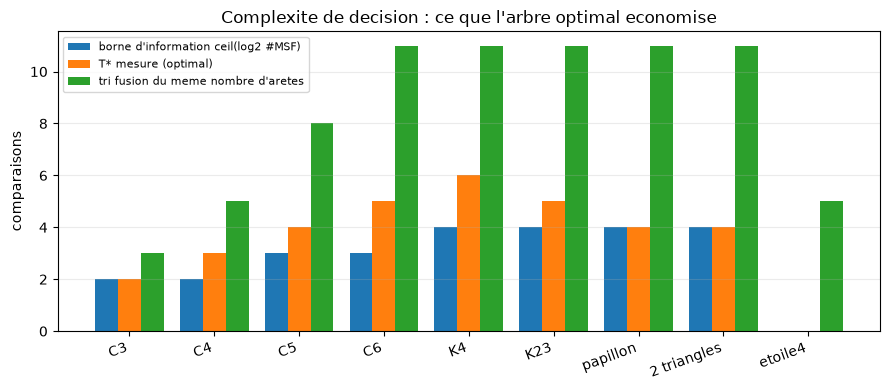

In [8]:
fig, ax = plt.subplots(figsize=(9.0, 4.0))
noms = [r[0] for r in resultats_t]
positions = range(len(noms))
largeur = 0.27
ax.bar([p - largeur for p in positions], [r[1] for r in resultats_t], largeur,
       label="borne d'information ceil(log2 #MSF)")
ax.bar(list(positions), [r[2] for r in resultats_t], largeur, label="T* mesure (optimal)")
ax.bar([p + largeur for p in positions], [r[3] for r in resultats_t], largeur,
       label="tri fusion du meme nombre d'aretes")
ax.set_xticks(list(positions))
ax.set_xticklabels(noms, rotation=20, ha="right")
ax.set_ylabel("comparaisons")
ax.set_title("Complexite de decision : ce que l'arbre optimal economise")
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

### Lecture de la figure

- **L'arbre optimal ne dépasse jamais le tri**, topologie par topologie : la barre du milieu est toujours plus basse que la barre de droite. Sur les six arêtes de `C6`, `K4`, `K23`, du papillon et des deux triangles, il utilise de `4` à `6` comparaisons là où le tri en demande `11` : entre un tiers et un peu plus de la moitié du coût.
- **L'écart entre les deux barres de gauche est mince mais réel.** Il atteint 2 sur `C6` (3 contre 5) comme sur `K4` (4 contre 6) : savoir *quel* arbre sort gagnant demande moins d'information que ce qu'un arbre de comparaison doit dépenser pour le savoir.
- **L'étoile est le seul cas où tout s'effondre.** Les deux premières barres sont nulles, la troisième vaut 5 : trier les arêtes d'un graphe qui n'a qu'un seul arbre couvrant est du travail entièrement inutile.

La figure donne donc un **fait** : sur ces graphes-là, le nombre de comparaisons nécessaire est une fraction du coût d'un tri. La question du preprint est de savoir si cette fraction reste bornée quand le nombre d'arêtes grandit — ou, ce qui revient au même, si `T*(m, n)` grandit comme `m`. Avant de lire la réponse, il faut comprendre la fonction qui figurait dans la meilleure borne connue jusqu'ici.

## 5. alpha(m, n) : l'inverse d'Ackermann, calculée exactement

La meilleure borne déterministe connue avant le preprint était, dans les termes des auteurs, `O(mα(m, n))`, « due to Chazelle [Cha00a] ». Et le texte précise ce qu'est ce `α` : « Here α is a two-parameter inverse-Ackermann function as in Tarjan's analysis of union–find [Tar75] ».

Une inverse d'Ackermann est souvent présentée comme « une fonction qui vaut au plus 4 en pratique ». C'est une affirmation. La cellule suivante la **calcule**.

### La convention employée, déclarée

L'inverse d'Ackermann n'a pas de définition unique : plusieurs conventions coexistent dans la littérature, et le preprint renvoie à l'analyse de Tarjan sans reprendre la formule. Pour qu'un calcul ait un sens, la convention doit être écrite. Ici, `A` est la fonction d'Ackermann-Peter (`A(0, n) = n + 1`, `A(m, 0) = A(m-1, 1)`, `A(m, n) = A(m-1, A(m, n-1))`), et deux conventions sont calculées côte à côte pour montrer que la conclusion ne dépend pas du choix :

- `alpha_>=` : le plus petit `i >= 1` tel que `A(i, m // n) >= ceil(log2 n)` ;
- `alpha_>` : le plus petit `i >= 1` tel que `A(i, m // n) > log2 n` (logarithme réel).

La cellule calcule aussi des valeurs exactes de `A` par la définition récursive, et compare les deux conventions aux points où elles risquent de différer.


In [9]:
def ackermann_plafonne(m: int, n: int, plafond: int) -> int:
    """A(m, n) d'Ackermann-Peter, bornee a plafond + 1 : on ne la compare qu'a un logarithme."""
    memo: dict[tuple[int, int], int] = {}

    def A(mm: int, nn: int) -> int:
        if (mm, nn) in memo:
            return memo[(mm, nn)]
        if mm == 0:
            val = nn + 1
        elif nn == 0:
            val = A(mm - 1, 1)
        else:
            interne = A(mm, nn - 1)
            val = plafond + 1 if interne > plafond else A(mm - 1, interne)
        val = min(val, plafond + 1)
        memo[(mm, nn)] = val
        return val

    return A(m, n)


def ackermann_exact(m: int, n: int) -> int:
    if m == 0:
        return n + 1
    if n == 0:
        return ackermann_exact(m - 1, 1)
    return ackermann_exact(m - 1, ackermann_exact(m, n - 1))


def alpha(m: int, n: int) -> int:
    """min{ i >= 1 : A(i, m // n) >= ceil(log2 n) } -- convention declaree, cf. texte."""
    cible = math.ceil(math.log2(n))
    i = 1
    while ackermann_plafonne(i, max(m // n, 0), cible) < cible:
        i += 1
    return i


def alpha_strict(m: int, n: int) -> int:
    """Seconde convention : min{ i >= 1 : A(i, m // n) > log2 n }, logarithme reel."""
    cible = math.log2(n)
    plafond = math.ceil(cible)
    i = 1
    while ackermann_plafonne(i, max(m // n, 0), plafond) <= cible:
        i += 1
    return i


print("Valeurs exactes d'Ackermann (convention Ackermann-Peter) :")
for (mm, nn) in [(1, 1), (2, 1), (2, 2), (3, 1), (3, 2), (3, 3), (3, 4)]:
    print(f"   A({mm},{nn}) = {ackermann_exact(mm, nn)}")
print("   A(4,1) = A(3, A(3,1)) = A(3,13) = 2^16 - 3 =", 2 ** 16 - 3)
print()
print(f"   {'n (avec m = n)':>18s} {'alpha >=':>9s} {'alpha >':>8s}")
for n in [10, 100, 1000, 10 ** 4, 10 ** 6, 10 ** 9, 10 ** 18]:
    print(f"   {n:>18d} {alpha(n, n):>9d} {alpha_strict(n, n):>8d}")
print()
print("   seuils de la convention >= :", [(k, alpha(k, k)) for k in [8, 9, 32, 33, 8192, 8193]])
print("   seuils de la convention >  :", [(k, alpha_strict(k, k)) for k in [8, 9, 32, 33, 65536, 65537]])
sys.set_int_max_str_digits(30000)
nb_chiffres = len(str(2 ** 65533))
print()
print("   2^65533 a", nb_chiffres, "chiffres.")
print("   pour tout n <= 2^65533 et tout m >= n : A(4, m // n) >= A(4, 1) = 65533 >= log2 n,")
print("   donc alpha <= 4 (convention >= ; stricte : pour tout n < 2^65533), et m*alpha(m,n) <= 4m.")
print("   m < n change la valeur : n = 10^18, m = n // 2 : alpha >=", alpha(10 ** 18 // 2, 10 ** 18))

Valeurs exactes d'Ackermann (convention Ackermann-Peter) :
   A(1,1) = 3
   A(2,1) = 5
   A(2,2) = 7
   A(3,1) = 13
   A(3,2) = 29
   A(3,3) = 61
   A(3,4) = 125
   A(4,1) = A(3, A(3,1)) = A(3,13) = 2^16 - 3 = 65533

       n (avec m = n)  alpha >=  alpha >
                   10         2        2
                  100         3        3
                 1000         3        3
                10000         4        4
              1000000         4        4
           1000000000         4        4
   1000000000000000000         4        4

   seuils de la convention >= : [(8, 1), (9, 2), (32, 2), (33, 3), (8192, 3), (8193, 4)]
   seuils de la convention >  : [(8, 2), (9, 2), (32, 3), (33, 3), (65536, 4), (65537, 4)]

   2^65533 a 19728 chiffres.
   pour tout n <= 2^65533 et tout m >= n : A(4, m // n) >= A(4, 1) = 65533 >= log2 n,
   donc alpha <= 4 (convention >= ; stricte : pour tout n < 2^65533), et m*alpha(m,n) <= 4m.
   m < n change la valeur : n = 10^18, m = n // 2 : alpha >= 5


### Lecture du résultat

**D'abord les valeurs de `A`, calculées par la définition.** `A(1,1) = 3`, `A(2,1) = 5`, `A(3,1) = 13`, `A(3,3) = 61`, et surtout `A(4,1) = A(3, A(3,1)) = A(3,13) = 65533`. Le saut est net dès le quatrième niveau : passer de `A(3, ·)` à `A(4, 1)` fait déjà 65533. C'est ce saut qui rend l'inverse si petite.

**Ensuite `alpha`, colonne par colonne.**

- `alpha(10, 10) = 2` ; `alpha(100, 100) = 3` ; à partir de `n = 10 000` et jusqu'à `10^18`, `alpha = 4`.
- Les **seuils** disent la même chose autrement. Avec la convention `>=`, `alpha` passe à 2 à `n = 9`, reste 2 jusqu'à 32, passe à 3 à 33, reste 3 jusqu'à 8192, et passe à 4 à 8193. La convention stricte décale le dernier seuil : elle exige `n = 65536` pour passer à 4. Les deux conventions **coïncident** sur `n = 9`, `n = 33`, puis de `n = 1000` à `n = 10^18` ; elles diffèrent sur `n = 8` et `n = 32`, et par construction autour de leur dernier seuil (8193 contre 65536).
- **La borne « 4 » tient jusqu'à des tailles absurdes.** `2^65533` a 19728 chiffres. Pour tout `n <= 2^65533` et tout `m >= n`, `A(4, m // n) >= A(4,1) = 65533 >= log2 n`, donc `alpha <= 4` — et par conséquent `m·alpha(m, n) <= 4m`. Autrement dit : sur **toute** entrée dont le nombre de sommets tient en 19728 chiffres, la borne `O(m alpha)` vaut au plus `4m`. Ce n'est pas une approximation, c'est une conséquence de deux quantités mesurées ci-dessus (`A(4,1) = 65533` et la taille de `2^65533`).
- **`alpha` dépend des deux paramètres, pas seulement de `n`.** Avec `n = 10^18` et `m = n // 2`, le rapport `m // n` vaut 0, et la fonction doit monter jusqu'à `i = 5` : `alpha >= 5`. C'est la raison d'être du second paramètre : c'est `m/n`, la densité, qui décide de l'argument d'Ackermann.

### Ce que cela change — et ce que cela ne change pas

Voici le point le plus délicat du carnet, et il faut le dire sans le gonfler.

`alpha` est une fonction si lente que, sur toute entrée de taille réalisable, elle vaut au plus 4. La différence entre une borne `O(m alpha(m, n))` et une borne `O(m)` est donc, pour toute entrée qui existe, un **facteur constant** — au plus 4 sur le nombre de comparaisons. L'apport du preprint n'est pas « un algorithme plus rapide de 4 fois » : c'est un changement de **classe asymptotique**. Une borne `O(m alpha)` n'est pas linéaire au sens de la théorie, même si, à toute taille réalisable, elle en diffère d'un facteur 4 ; et c'est précisément ce « pas linéaire » qui laissait le problème ouvert depuis Chazelle.

Une réserve, mesurée : la constante **cachée** dans le `O(m)` du preprint n'est pas donnée explicitement dans le texte lu. Le preprint énonce `O(m)` et une constante `C_epsilon` dans son lemme technique (`epsilon` pouvant être pris à `1/8`), mais aucun nombre ne permet de dire « l'algorithme fait au plus `c·m` comparaisons avec `c = ...` ». Comparer les 4 comparaisons par arête de la borne `4m` à la constante réelle du nouvel algorithme est donc **hors d'atteinte** avec les moyens de ce carnet. C'est consigné comme ouvert en section 11.

Une dernière remarque, qui prépare la section suivante : cette borne `4m` n'est pas la borne d'un algorithme, c'est la borne d'une **structure** — l'union-find de Kruskal, dont l'analyse donne `alpha`. La cellule suivante mesure cette structure séparément.


In [10]:
print("Union-Find de Kruskal : appels a trouver et pas de compression (fractionnement)")
print(f"   {'n':>6s} {'m':>7s} {'appels':>9s} {'pas':>8s} {'pas/appel':>10s} {'pas/arete':>10s}")
for n in [500, 1000, 2000, 4000, 8000, 16000]:
    aretes, w = graphe_aleatoire(n, 3.0, graine=n)
    m = len(aretes)
    uf = UnionFind(n)
    kruskal(list(range(m)), aretes, w, Comparaisons(), uf)
    print(f"   {n:>6d} {m:>7d} {uf.appels:>9d} {uf.pas:>8d} {uf.pas / uf.appels:>10.3f}"
          f" {uf.pas / m:>10.3f}")

Union-Find de Kruskal : appels a trouver et pas de compression (fractionnement)
        n       m    appels      pas  pas/appel  pas/arete
      500    1500      3000     3763      1.254      2.509
     1000    3000      6000     8184      1.364      2.728
     2000    6000     12000    17425      1.452      2.904
     4000   12000     24000    37044      1.544      3.087


     8000   24000     48000    79500      1.656      3.312

    16000   48000     96000   167021      1.740      3.480

### Lecture du résultat — l'alpha de la structure n'est pas celui du problème

- **Deux appels à `trouver` par arête, exactement.** Pour `n = 500`, `m = 1500` arêtes donnent `3000` appels ; pour `n = 16000`, `48000` arêtes donnent `96000` appels. La raison est structurelle : chaque arête de l'ordre trié passe par `unir`, qui cherche la racine de chacune de ses deux extrémités. Ce nombre ne dépend pas des poids.
- **Les pas de compression, eux, croissent.** De `1,254` pas par appel à `n = 500` à `1,740` à `n = 16000`, soit environ sept pour cent de plus à chaque doublement. Rapporté aux arêtes : de `2,5` à `3,5` pas par arête.

Deux mises en garde, toutes deux indispensables pour ne pas surinterpréter la table.

**Première mise en garde : la structure mesurée n'est pas celle du théorème `O(alpha)`.** L'union-find de ce carnet compresse les chemins (par fractionnement) mais **n'unit pas par rang ni par taille** : `unir` accroche toujours la racine de `a` sous celle de `b`. La borne classique pour cette structure est `O(log n)` par opération, pas `O(alpha)`. La borne `alpha` de Tarjan vaut pour la compression **accompagnée** d'une union par taille ou par rang, et c'est une borne **amortie sur une séquence** d'opérations, pas un compteur que l'on peut lire appel par appel. La table mesure donc le coût d'une structure simplifiée : elle montre qu'il est petit et croît lentement, elle ne mesure pas `alpha`.

**Deuxième mise en garde : `alpha` est la borne d'une structure, pas celle du problème.** C'est exactement le piège que le preprint signale. Ses auteurs racontent que l'idée du temps linéaire a longtemps fait doute, « largely due to Ω(mα) lower bounds for related union-find data structures (see [Tar79b]), and variants of the MST problem [Pet06] ». Et le texte précise la variante en question : « Pettie [Pet06] ruled out one natural approach by proving that online verification, in which path-maximum queries arrive one at a time, indeed requires Ω(mα(m, n) + n) comparisons ». Autrement dit : un algorithme qui traiterait les requêtes une à une, en interrogeant une structure de chemins, doit payer `alpha`. Le théorème du preprint dit que le problème, lui, ne l'exige pas — à condition de ne pas travailler en ligne. La section 8 mesure ce que coûte, sur un jouet, la structure de chemins la plus naïve qui soit : une remontée pas à pas.


## 6. Le filtre : arêtes lourdes, arêtes légères, et les deux pièges

Tout le preprint tourne autour d'un geste : **jeter des arêtes sans perdre l'arbre**. C'est un théorème classique, que les auteurs rappellent ainsi :

> « For any forest F ⊆ G, let us call an edge F-heavy if it is heavier than every edge on the F-path between its endpoints, and F-light otherwise. By the cycle property, F-heavy edges can be discarded, and an adaptation of the verification algorithm identifies all of them in linear time [DRT92, KKT95]. »

Le preprint emploie aussi une seconde notion, définie à la section 1.2 juste avant son lemme principal :

> « for a graph G = (V, E) and a forest F ⊆ E, we say that an edge e ∈ E is supported by F, if the endpoints of e are connected by F≤w(e). In words, this is simply asking that if one adds the edge e to the forest F, then the resulting cycle uses edges of weight only ≤ w(e). »

Les deux notions se lisent sur une seule quantité : le maximum du chemin de `F` entre les extrémités de l'arête. Une arête hors de `F` est **lourde** si son poids dépasse **strictement** ce maximum, **légère** sinon. Elle est **supportée** si son poids est supérieur ou **égal** à ce maximum. À poids distincts, une arête hors de `F` est donc supportée exactement quand elle est lourde, et le lemme 1.2 compte sous `U(F)` les arêtes **non** supportées : ce sont celles que le filtre garde. Une arête de `F` elle-même est dans `F`. Une arête dont les extrémités ne sont pas reliées par `F` n'a pas de chemin, donc pas de verdict.

### Les deux pièges, et pourquoi ils comptent

1. **L'inégalité stricte est ce qui protège `F`.** Une arête n'est lourde que si `max(chemin) < w(e)` : une arête dont le poids **égale** le maximum du chemin n'est pas lourde. Ce cas n'est pas théorique — une arête de `F` est seule sur le chemin de `F` entre ses extrémités, donc son poids égale toujours ce maximum. Une règle qui ne garderait une arête que si `w(e) < max(chemin)` jetterait toutes les arêtes de `F`. La cellule ci-dessous montre la règle juste et cette règle fausse côte à côte, sur un triangle, le plus petit graphe qui contienne un cycle.
2. **Le chemin se lit dans le graphe courant, pas dans le graphe d'origine.** Quand l'algorithme a déjà contracté des composantes (phases de Borůvka), les extrémités d'une arête sont des **composantes** ; chercher le chemin entre les sommets d'origine donnerait un chemin qui traverse des arêtes déjà contractées, et un verdict faux. La classe `CheminMax` reçoit pour cela l'union-find courant : sans lui, c'est l'identité, et le chemin est cherché entre les sommets d'origine.

### Ce que cette section construit, et ce qu'elle ne construit pas

Ce qui est implémenté ici est un **classement exact**, arête par arête : pour chaque arête, un verdict — lourde, légère, dans `F`, ou sans chemin. Ce n'est pas le certificat du preprint. Le lemme 1.2 (énoncé à la section 9) garantit qu'une procédure déterministe construit, en `O_ε(m)` comparaisons de poids hors ses appels à des sous-instances, une forêt `F` pour laquelle `|F| + |U(F)| + Σ|Ei| <= εm + C_ε √(nm)`. Les auteurs résument son rôle en une phrase : elle « supports many of the original edges ». Classer toutes les arêtes d'un graphe et produire un certificat qui **réduit** le problème sont deux gestes différents.

Et le classement, tel qu'il est écrit ici, ne coûte pas une comparaison par arête : le maximum d'un chemin s'obtient en remontant ce chemin pas à pas. La cellule compte ces comparaisons à part, dans `parcours` ; la section 8 mesure ce qu'elles coûtent quand `n` grandit.


In [11]:
class CheminMax:
    """Pour une foret F : poids maximum sur le chemin de F entre deux sommets.

    Les extremites sont lues dans le graphe COURANT : si `uf` contracte deja des sommets
    (phases de Boruvka), le chemin est cherche entre les composantes, pas entre les
    sommets d'origine. Sans `uf`, c'est l'identite.
    """

    def __init__(self, F: list[int], aretes: list[tuple[int, int]], w: list[float],
                 uf: UnionFind | None = None) -> None:
        identite = uf is None
        adj: dict[int, list[tuple[int, float]]] = {}
        for e in F:
            u, v = aretes[e]
            if not identite:
                u, v = uf.trouver(u), uf.trouver(v)
            adj.setdefault(u, []).append((v, w[e]))
            adj.setdefault(v, []).append((u, w[e]))
        self.parent: dict[int, int] = {}
        self.vers_parent: dict[int, float] = {}
        self.profondeur: dict[int, int] = {}
        self.racine: dict[int, int] = {}
        self.verdicts: int = 0
        self.pas: int = 0
        self.parcours: int = 0
        for s in adj:
            if s in self.parent:
                continue
            self.parent[s] = s
            self.profondeur[s] = 0
            self.racine[s] = s
            pile = [s]
            while pile:
                x = pile.pop()
                for y, wy in adj[x]:
                    if y not in self.parent:
                        self.parent[y] = x
                        self.vers_parent[y] = wy
                        self.profondeur[y] = self.profondeur[x] + 1
                        self.racine[y] = s
                        pile.append(y)

    def relies(self, u: int, v: int) -> bool:
        return u in self.racine and v in self.racine and self.racine[u] == self.racine[v]

    def maximum(self, u: int, v: int) -> float:
        """Poids le plus lourd sur le chemin de F entre u et v (appeles seulement si reliees).

        Un chemin de longueur k (k aretes de F) coute k - 1 comparaisons de poids : la premiere
        arete devient le maximum sans comparaison, chacune des suivantes est comparee au maximum
        courant. Ces comparaisons ont lieu ENTRE ARETES DE F : l'instrument `cmp` ne les voit
        pas, elles sont comptees ici, dans `parcours`. `pas` compte les aretes parcourues et
        `verdicts` les appels.
        """
        if u == v:
            return 0.0
        self.verdicts += 1
        if self.profondeur[u] < self.profondeur[v]:
            u, v = v, u
        m = self.vers_parent[u]
        self.pas += 1
        u = self.parent[u]
        while u != v:
            if self.profondeur[u] < self.profondeur[v]:
                u, v = v, u
            self.pas += 1
            self.parcours += 1
            if self.vers_parent[u] > m:
                m = self.vers_parent[u]
            u = self.parent[u]
        return m


def classifier(E: list[int], aretes: list[tuple[int, int]], w: list[float], F: list[int],
               chemin: CheminMax, cmp: Comparaisons, uf: UnionFind | None = None) -> dict[int, str]:
    """'F' | 'lourde' | 'legere' | 'sans_chemin'. Lourde ssi plus lourde que TOUTE arete du chemin.

    Lourde = F-heavy du preprint (jetable) ; legere = F-light (gardee) ; ni l'un ni l'autre si
    les extremites ne sont pas reliees par F.
    """
    dans_F = set(F)
    resultat: dict[int, str] = {}
    for e in E:
        u, v = aretes[e]
        if uf is not None:
            u, v = uf.trouver(u), uf.trouver(v)
        if e in dans_F:
            resultat[e] = "F"
        elif not chemin.relies(u, v):
            resultat[e] = "sans_chemin"
        elif cmp.inferieur(chemin.maximum(u, v), w[e]):
            resultat[e] = "lourde"
        else:
            resultat[e] = "legere"
    return resultat


def classifier_piege(E: list[int], aretes: list[tuple[int, int]], w: list[float], F: list[int],
                     chemin: CheminMax, cmp: Comparaisons) -> dict[int, str]:
    """La regle fausse : garder si strictement plus legere que le maximum du chemin."""
    resultat: dict[int, str] = {}
    for e in E:
        u, v = aretes[e]
        if not chemin.relies(u, v):
            resultat[e] = "sans_chemin"
        elif cmp.inferieur(w[e], chemin.maximum(u, v)):
            resultat[e] = "legere"
        else:
            resultat[e] = "lourde"
    return resultat


aretes_petit = [(0, 1), (1, 2), (0, 2)]
w_petit = [1.0, 2.0, 3.0]
F_petit = [0, 1]
chemin_petit = CheminMax(F_petit, aretes_petit, w_petit)
juste = classifier([0, 1, 2], aretes_petit, w_petit, F_petit, chemin_petit, Comparaisons())
faux = classifier_piege([0, 1, 2], aretes_petit, w_petit, F_petit, chemin_petit, Comparaisons())
print("Triangle 0-1 (1), 1-2 (2), 0-2 (3) ; F = les deux aretes les plus legeres :")
print("   regle juste :", juste)
print("   regle fausse :", faux, "-> elle jette les", sum(1 for c in faux.values() if c == "lourde"),
      "aretes, dont les 2 de F : il ne reste aucun arbre")

Triangle 0-1 (1), 1-2 (2), 0-2 (3) ; F = les deux aretes les plus legeres :
   regle juste : {0: 'F', 1: 'F', 2: 'lourde'}
   regle fausse : {0: 'lourde', 1: 'lourde', 2: 'lourde'} -> elle jette les 3 aretes, dont les 2 de F : il ne reste aucun arbre


### Lecture du résultat

Sur le triangle (arêtes de poids 1, 2 et 3, avec `F` = les deux plus légères) :

- **La règle juste** rend `{0: 'F', 1: 'F', 2: 'lourde'}` : les deux arêtes de `F` sont protégées par leur appartenance à `F`, et la troisième est reconnue lourde parce que son chemin dans `F` a un maximum de 2, strictement inférieur à son poids 3. Le cycle `0-1-2` n'utilise que des arêtes plus légères : par la propriété du cycle, l'arête `0-2` ne peut être dans aucun arbre couvrant minimal.
- **La règle fausse** rend `{0: 'lourde', 1: 'lourde', 2: 'lourde'}` : elle jette les trois arêtes, dont les deux de `F`. Il ne reste plus rien pour construire un arbre.

La règle fausse porte en réalité **deux** défauts, et c'est ce que le triangle rend visible d'un coup :

1. **Elle ne protège pas les arêtes de `F`.** Une arête déjà retenue dans la forêt ne se rejette jamais : c'est le seul objet que le filtre doit conserver par construction. La règle juste teste l'appartenance à `F` avant toute comparaison ; la règle fausse compare toutes les arêtes, celles de `F` comprises.
2. **Elle lit l'égalité comme de la lourdeur.** Sa comparaison demande `w(e) < max(chemin)` pour garder ; une arête dont le poids **égale** le maximum du chemin est donc rejetée. Or la définition du preprint est explicite — lourde signifie « heavier than **every** edge on the F-path », donc strictement plus lourde que toutes ; égaler le maximum ne suffit pas. Et l'égalité est la situation habituelle d'une arête de `F` : seule sur le chemin de `F` entre ses extrémités, elle en est le maximum. C'est ainsi que la règle fausse jette les deux arêtes de `F`. Sur la troisième arête, plus lourde que le maximum de son chemin, les deux règles sont d'accord : elle est lourde.

C'est pourquoi `classifier` teste trois choses dans cet ordre : l'appartenance à `F`, l'existence d'un chemin, puis la comparaison stricte. Sans la comparaison stricte, une arête de `F` serait jugée lourde ; sans le test du chemin, on chercherait un maximum entre deux sommets que `F` ne relie pas.

**Combien coûte un verdict ?** Côté instrument, **une** comparaison : le maximum de son chemin contre son poids. Mais ce maximum, `maximum` l'obtient en remontant le chemin de `F`. La première arête du chemin devient le maximum sans rien comparer ; chacune des suivantes est comparée au maximum courant. Un chemin de `k` arêtes de `F` coûte donc `k − 1` comparaisons — entre poids d'arêtes de `F`, donc invisibles pour l'instrument. Ce sont pourtant des comparaisons de poids, au sens du modèle de la section 1. La classe les compte donc à part, dans trois attributs : `verdicts` (requêtes qui parcourent un chemin), `pas` (arêtes de `F` parcourues) et `parcours` (comparaisons entre poids d'arêtes de `F`, soit `pas − verdicts`). Sur le triangle, la remontée est courte : deux pas, une comparaison. Elle ne le reste pas quand la forêt grandit : c'est ce que mesurent les deux sections suivantes.

Reste le piège de la petite taille : ce triangle ne prouve pas que la règle est correcte en général, il prouve seulement qu'elle n'est pas **trivialement** fausse. Le fait général est le théorème du cycle, cité plus haut ; ce qui est mesuré ici est que l'implémentation ne s'en écarte pas sur un cas où deux implémentations plausibles divergent.


## 7. La route randomisée : échantillonner puis filtrer

Avant le résultat déterministe, la route connue passait par le hasard. Le preprint la résume en deux phrases (section 1, puis section 1.2) :

> « Klein and Tarjan [KT94], and later Karger, Klein, and Tarjan [KKT95], gave a randomized algorithm that always returns an MST and runs in linear time both in expectation and with high probability. »

> « Their algorithm alternates between so-called "Borůvka phases", which shrink the number of vertices, with the new idea of sampling and filtering, which shrink the number of edges. The crucial lemma which underlies their result shows that if each edge is sampled independently with probability 0 < p ≤ 1 and F is the sample's minimum spanning forest, then the expected number of F-light edges of G is at most n/p. This idea of using Borůvka phases to reduce vertices, and "filtering" to reduce edges, will also re-appear in the algorithm we present below (though the filtering will naturally require an entirely different approach to achieve a deterministic guarantee). »

### Ce que dit le lemme, et ce qu'il ne dit pas

Le lemme est une borne sur une **espérance**. Il affirme que, en moyenne sur les tirages de l'échantillon, il reste au plus `n/p` arêtes non lourdes. Il n'affirme **pas** que chaque tirage respecte `n/p` : un tirage donné peut dépasser la borne, et c'est précisément ce que la mesure ci-dessous va montrer. C'est le genre d'écart qui sépare un énoncé probabiliste d'une garantie déterministe, et c'est la raison pour laquelle la route randomisée ne suffisait pas.

La cellule suivante mesure, sur deux densités et trois probabilités :

- le nombre moyen d'arêtes qui **survivent** au filtre (celles qui ne sont pas classées lourdes) ;
- son erreur type, sur 2000 tirages indépendants ;
- le rapport à la borne `n/p` ;
- le minimum, le maximum, et le nombre de tirages qui **dépassent** la borne.


In [12]:
print("Lemme d'echantillonnage : E[aretes F-legeres] <= n/p, mesure sur n = 100.")
tirages_histo: list[int] = []
for ratio in [3.0, 10.0]:
    n = 100
    aretes, w = graphe_aleatoire(n, ratio, graine=11)
    m = len(aretes)
    print(f"   n={n} m={m} (m/n={ratio:.0f})")
    print(f"   {'p':>5s} {'n/p':>7s} {'moyenne':>8s} {'erreur type':>12s} {'ratio':>6s} {'min':>4s} {'max':>4s} {'>borne':>7s}")
    for p in [0.5, 0.3, 0.2]:
        rng = random.Random(7)
        R = 2000
        valeurs: list[int] = []
        for _ in range(R):
            echantillon = [e for e in range(m) if rng.random() < p]
            F = kruskal(echantillon, aretes, w, Comparaisons(), UnionFind(n))
            classes = classifier(list(range(m)), aretes, w, F, CheminMax(F, aretes, w), Comparaisons())
            valeurs.append(sum(1 for c in classes.values() if c != "lourde"))
        borne = n / p
        moyenne = sum(valeurs) / R
        variance = sum((v - moyenne) ** 2 for v in valeurs) / (R - 1)
        print(f"   {p:>5.2f} {borne:>7.0f} {moyenne:>8.2f} {math.sqrt(variance / R):>12.2f}"
              f" {moyenne / borne:>6.3f} {min(valeurs):>4d} {max(valeurs):>4d}"
              f" {sum(1 for v in valeurs if v > borne):>7d}")
        if ratio == 10.0 and p == 0.5:
            tirages_histo = valeurs
print()
print("   decomposition d'un tirage (n=100, m=1000, p=0.5) :")
aretes, w = graphe_aleatoire(100, 10.0, graine=11)
rng = random.Random(3)
echantillon = [e for e in range(len(aretes)) if rng.random() < 0.5]
F = kruskal(echantillon, aretes, w, Comparaisons(), UnionFind(100))
cmp = Comparaisons()
chemin = CheminMax(F, aretes, w)
classes = classifier(list(range(len(aretes))), aretes, w, F, chemin, cmp)
print("   ", dict(Counter(classes.values())), " aretes comparees au maximum de leur chemin :", cmp.n)
print("    comparaisons internes de ces parcours de chemin :", chemin.parcours)
print("    longueur moyenne d'un chemin parcouru (en aretes de F) :",
      f"{chemin.pas / chemin.verdicts:.2f}")

Lemme d'echantillonnage : E[aretes F-legeres] <= n/p, mesure sur n = 100.
   n=100 m=300 (m/n=3)
       p     n/p  moyenne  erreur type  ratio  min  max  >borne


    0.50     200   188.69         0.27  0.943  151  230     330


    0.30     333   264.06         0.29  0.792  214  296       0


    0.20     500   293.08         0.12  0.586  262  300       0
   n=100 m=1000 (m/n=10)
       p     n/p  moyenne  erreur type  ratio  min  max  >borne


    0.50     200   198.08         0.31  0.990  157  250     832


    0.30     333   328.73         0.60  0.986  245  426     794


    0.20     500   485.62         0.92  0.971  363  643     710

   decomposition d'un tirage (n=100, m=1000, p=0.5) :
    {'lourde': 781, 'legere': 120, 'F': 99}  aretes comparees au maximum de leur chemin : 901
    comparaisons internes de ces parcours de chemin : 8369
    longueur moyenne d'un chemin parcouru (en aretes de F) : 10.29


### Lecture du résultat

**L'espérance est bien sous la borne, partout.** Les six lignes donnent des rapports `moyenne / (n/p)` de `0,586` à `0,990` : jamais au-dessus. L'erreur type est petite (`0,12` à `0,92`), ce qui rend les moyennes fiables.

**Chaque tirage, en revanche, ne respecte rien.** À densité 3 et `p = 1/2`, `330` tirages sur `2000` dépassent la borne de 200, avec un maximum à `230`. À densité 10 et `p = 1/2`, c'est `832` sur `2000` — plus de quatre tirages sur dix — avec un maximum à `250`. Le lemme est donc exactement ce qu'il annonce : une borne sur une **moyenne**, pas un garde-fou par tirage.

**La borne n'est pas atteinte par le haut non plus.** À densité 3 et `p = 1/5`, la moyenne vaut `293` pour une borne de `500` : la borne est lâche dans ce régime. Elle est en revanche presque serrée à densité 10, où les rapports montent à `0,971`, `0,986` et `0,990`.

**Ce que coûte la mesure elle-même.** Sur le tirage décomposé (`m = 1000`), `901` arêtes sont comparées au maximum de leur chemin — une comparaison chacune. Elles se répartissent en `781` lourdes et `120` légères ; les `99` arêtes de `F` ne sont pas comparées. Mais le maximum d'un chemin ne tombe pas du ciel : `maximum` le trouve en remontant le chemin pas à pas. Sur ce tirage, ces remontées ont coûté `8369` comparaisons de poids entre arêtes de `F` — plus de neuf fois le classement lui-même. La cause se lit sur la dernière ligne : les chemins parcourus ont en moyenne `10,29` arêtes de `F`, soit `9,29` comparaisons internes par arête classée. L'énoncé cité en section 6, « an adaptation of the verification algorithm identifies all of them in linear time », repose donc sur un **algorithme de vérification**, pas sur une remontée naïve. La section 8 mesure ce que coûte la remontée quand `n` grandit.

Ce constat — moyenne sûre, tirage non sûr — est ce qui justifie la section suivante : comparer trois façons de **choisir** l'échantillon, dont deux déterministes.



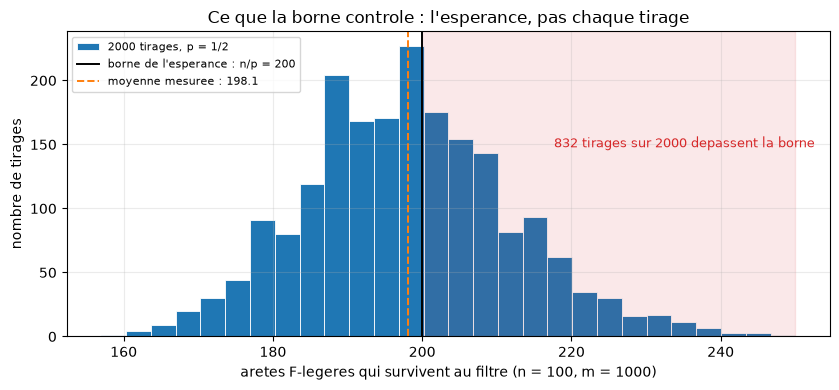

In [13]:
moyenne_histo = sum(tirages_histo) / len(tirages_histo)
au_dessus = sum(1 for v in tirages_histo if v > 200)
fig, ax = plt.subplots(figsize=(8.5, 4.0))
ax.hist(tirages_histo, bins=28, edgecolor="white", linewidth=0.6, label="2000 tirages, p = 1/2")
ax.axvline(200, color="black", linewidth=1.4, label="borne de l'esperance : n/p = 200")
ax.axvline(moyenne_histo, color="tab:orange", linewidth=1.4, linestyle="--",
           label=f"moyenne mesuree : {moyenne_histo:.1f}")
ax.axvspan(200, max(tirages_histo), color="tab:red", alpha=0.10)
ax.annotate(f"{au_dessus} tirages sur 2000 depassent la borne",
            xy=(0.98, 0.62), xycoords="axes fraction", ha="right", fontsize=9, color="tab:red")
ax.set_xlabel("aretes F-legeres qui survivent au filtre (n = 100, m = 1000)")
ax.set_ylabel("nombre de tirages")
ax.set_title("Ce que la borne controle : l'esperance, pas chaque tirage")
ax.legend(fontsize=8)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

### Lecture de la figure

L'histogramme porte les `2000` tirages de la ligne `p = 1/2` à densité 10.

- La distribution a la forme d'une **cloche**, centrée sur `198`, à gauche de la borne `200`. C'est l'illustration du lemme : en moyenne, le filtre laisse passer moins de `n/p` arêtes.
- La zone teintée à droite de la borne contient `832` tirages sur `2000`. La borne de l'espérance coupe donc la cloche : elle n'est pas une **barrière**, c'est une **moyenne majorée**.
- La largeur de la cloche va d'environ `157` à `250`. Aucun tirage ne s'approche des `1000` arêtes du graphe : le filtre a bien fait son travail sur chaque tirage, simplement pas avec la même marge.

Un algorithme randomisé peut se satisfaire de cette garantie : il sait qu'**en moyenne** le nombre d'arêtes diminue, et il borne son espérance de coût. Un algorithme déterministe ne le peut pas : il doit être sûr que le nombre d'arêtes diminue **à chaque** appel, sur **toute** entrée. La question devient alors : sans hasard, comment choisir un échantillon dont on puisse garantir quelque chose ?


### Trois façons de choisir l'échantillon — déterministe ou randomisé, montré par une expérience

La question « déterministe ou randomisé » se laisse réduire à un geste concret : **comment choisir les 500 arêtes de l'échantillon parmi les 1000** ? Trois réponses sont comparées sur le même graphe (`n = 100`, `m = 1000`).

| Choix | Comparaisons pour choisir | Regarde-t-il les poids ? | Garantie |
|---|---|---|---|
| **Aveugle** : les 500 premières arêtes par indice | 0 | non | aucune |
| **Aléatoire** : chaque arête avec probabilité `1/2` | 0 | non | en espérance seulement |
| **Tri complet** : les 500 plus légères | un tri | oui | déterministe |

Chaque choix est éprouvé sur **deux** jeux de poids :

- des **poids ordinaires** (permutation fixée d'avance de `1..1000`) ;
- des **poids adverses**, construits en connaissant le choix aveugle : les 500 arêtes de plus petit indice reçoivent les poids `501..1000`, les autres les poids `1..500`. L'échantillon aveugle est alors constitué des **500 arêtes les plus lourdes** du graphe.

La colonne mesurée est le nombre d'arêtes **non lourdes** qui survivent au filtre : moins il y en reste, plus le filtre a servi.

La règle du jeu est à lire précisément. L'aléatoire et l'aveugle ont le même coût de choix — zéro comparaison — et le même aveuglement devant les poids. Seul le hasard de l'un le protège : un adversaire peut concevoir des poids qui ruinent un choix **fixe**, il ne peut pas en concevoir qui ruinent **en moyenne** un choix aléatoire. Le tri complet, lui, est déterministe et protégé, mais il paie pour l'être.


In [14]:
print("Trois facons de choisir l'echantillon (n = 100, m = 1000, |S| = 500) :")
n = 100
aretes, w = graphe_aleatoire(n, 10.0, graine=21)
m = len(aretes)
moitie = m // 2
w_adv = [0.0] * m
for k, e in enumerate(range(m)):
    w_adv[e] = float(moitie + 1 + k) if e < moitie else float(1 + k - moitie)


def legeres_de(F: list[int], poids: list[float]) -> tuple[int, dict[int, str]]:
    classes = classifier(list(range(m)), aretes, poids, F, CheminMax(F, aretes, poids), Comparaisons())
    return sum(1 for c in classes.values() if c != "lourde"), classes


# 1. Choix aveugle : les 500 premieres aretes par indice, sans regarder les poids.
F_adv = kruskal(list(range(moitie)), aretes, w_adv, Comparaisons(), UnionFind(n))
F_ord = kruskal(list(range(moitie)), aretes, w, Comparaisons(), UnionFind(n))
aveugle = (0, legeres_de(F_adv, w_adv)[0], legeres_de(F_ord, w)[0])
# 2. Choix aleatoire : chaque arete avec probabilite 1/2, sans regarder les poids (moyenne sur 2000 tirages).
rng_choix = random.Random(5)
R = 2000
somme = [0, 0]
for _ in range(R):
    echantillon = [e for e in range(m) if rng_choix.random() < 0.5]
    somme[0] += legeres_de(kruskal(echantillon, aretes, w_adv, Comparaisons(), UnionFind(n)), w_adv)[0]
    somme[1] += legeres_de(kruskal(echantillon, aretes, w, Comparaisons(), UnionFind(n)), w)[0]
aleatoire = (0, somme[0] / R, somme[1] / R)
# 3. Choix informe : tri complet des poids, on garde les 500 plus legeres.
cmp_adv, cmp_ord = Comparaisons(), Comparaisons()
F_tri_adv = kruskal(tri_fusion(list(range(m)), w_adv, cmp_adv)[:moitie], aretes, w_adv, Comparaisons(), UnionFind(n))
F_tri_ord = kruskal(tri_fusion(list(range(m)), w, cmp_ord)[:moitie], aretes, w, Comparaisons(), UnionFind(n))
tri = (f"{cmp_adv.n} / {cmp_ord.n}", legeres_de(F_tri_adv, w_adv)[0], legeres_de(F_tri_ord, w)[0])
print(f"   {'choix':>34s} {'pour choisir':>13s} {'poids adverses':>15s} {'poids ordinaires':>17s}")
for libelle, (cout, legers_adv, legers_ord) in [("aveugle (500 premiers indices)", aveugle),
                                                (f"aleatoire p = 1/2 (moyenne {R})", aleatoire),
                                                ("tri complet (500 plus legere)", tri)]:
    adv = f"{legers_adv:.2f}" if isinstance(legers_adv, float) else str(legers_adv)
    ordinaire = f"{legers_ord:.2f}" if isinstance(legers_ord, float) else str(legers_ord)
    print(f"   {libelle:>34s} {str(cout):>13s} {adv:>15s} {ordinaire:>17s}")

Trois facons de choisir l'echantillon (n = 100, m = 1000, |S| = 500) :


                                choix  pour choisir  poids adverses  poids ordinaires
       aveugle (500 premiers indices)             0             599               172
     aleatoire p = 1/2 (moyenne 2000)             0          197.62            198.00
        tri complet (500 plus legere)   4932 / 8694              99                99


### Lecture du résultat — ce que l'expérience établit

La table se lit ligne par ligne, en comparant les deux colonnes de poids. Dans la colonne « Pour choisir », les deux nombres de la dernière ligne suivent l'ordre des deux colonnes de poids : `4932` comparaisons pour trier les poids adverses, `8694` pour trier les poids ordinaires.

| Choix | Pour choisir | Poids adverses | Poids ordinaires |
|---|---|---|---|
| aveugle | 0 | **599** | 172 |
| aléatoire | 0 | **197,62** | 198,00 |
| tri complet | 4932 / 8694 | **99** | 99 |

1. **Un choix déterministe et aveugle est ruinable, sans qu'on lui coûte une comparaison.** Sur des poids ordinaires, l'échantillon aveugle laisse passer `172` arêtes — honnête. Sur des poids construits **contre lui**, il en laisse passer `599` : plus du triple. Le mécanisme est lisible : l'échantillon est fait des 500 arêtes les plus lourdes, leur forêt ne sert à rien pour écarter les arêtes légères, et les 500 arêtes légères traversent toutes le filtre, plus `99` autres.
2. **Le hasard, au même coût, résiste.** L'échantillon aléatoire coûte lui aussi `0` comparaison et ne regarde pas plus les poids ; sur les **mêmes** poids adverses, il laisse passer `197,62` arêtes en moyenne — la même valeur (`198,00`) que sur des poids ordinaires. Le lemme d'échantillonnage le garantit : sa borne porte sur l'espérance, quels que soient les poids. Un adversaire qui connaît l'algorithme ne peut donc pas construire de poids qui ruinent la **moyenne** d'un tirage aléatoire.
3. **La détermination informée se paie.** Trier et garder les 500 plus légères donne le meilleur filtre, `99` arêtes survivantes dans les deux cas — exactement la taille de la forêt échantillon. Mais il a fallu `8694` comparaisons sur des poids ordinaires, soit `97 %` du pire cas `C(1000) = 8977` d'un tri de 1000 éléments. Le filtre est gratuit ; c'est le **choix** qui coûte un tri.

**Conclusion de l'expérience.** À trois ingrédients — coût du choix, regard sur les poids, garantie — aucune des trois méthodes n'a tout : l'aveugle est gratuit et sans garantie, l'aléatoire est gratuit et garanti en espérance, le tri est garanti et coûteux. C'est précisément le vide que comble le preprint : une façon **déterministe** de produire la forêt qui sert à filtrer, **garantie sur toute entrée**, pour un nombre linéaire de comparaisons (lemme 1.2, section 9). Le théorème n'est pas reproduit ici ; l'expérience montre seulement pourquoi les deux voies évidentes ne suffisaient pas.


## 8. Le squelette : Borůvka, échantillon, filtre, socle

L'algorithme du preprint n'est pas reproduit ici : il repose sur une procédure de certificat déterministe (lemme 1.2) dont l'énoncé est donné en section 9, et qui n'est pas implémentée dans ce carnet. Ce que cette section **mesure**, c'est le **squelette** commun à la route randomisée des années 1990 et à l'algorithme du preprint, tel que les auteurs le décrivent : « Borůvka phases » pour réduire les sommets, « filtering » pour réduire les arêtes, et on recommence.

**Avertissement, à lire avant la table.** Le programme ci-dessous est un **jouet inspiré de Karger–Klein–Tarjan** : il échantillonne **au hasard**. Il est donc randomisé, et ce n'est **pas** l'algorithme du preprint. Il sert à voir le squelette fonctionner et à mesurer ce que chaque étape apporte ; il ne démontre rien de déterministe.

### Le squelette, en quatre gestes

1. **Cas de base (socle).** S'il reste peu d'arêtes (`m <= 1,5 n`), on termine par un algorithme simple.
2. **Phases de Borůvka.** Chaque composante garde son arête sortante la plus légère, qui appartient à l'arbre ; on contracte. Le texte des auteurs : « every phase at least halves the number of vertices ».
3. **Échantillon et récursion.** On tire chaque arête avec probabilité `1/2`, on calcule récursivement la forêt couvrante minimale de l'échantillon.
4. **Filtre et récursion.** On écarte les arêtes lourdes pour cette forêt (section 6), et on recommence sur les survivantes.

### Trois compteurs, parce que l'instrument ne voit pas tout

L'instrument `cmp` compte les comparaisons faites **à travers lui** : le tri du socle, les choix des phases de Borůvka, et — dans le filtre — une comparaison par arête classée (le maximum de son chemin contre son poids). Il ne voit pas les comparaisons internes de `CheminMax.maximum`, qui remonte le chemin de `F` en comparant deux poids d'arêtes de `F` à chaque pas après le premier (section 6). Ce sont pourtant des comparaisons de poids, au sens du modèle de la section 1.

`CheminMax` tient donc trois attributs, nuls pour chaque nouveau filtre et additionnés sur toute l'exécution : `verdicts` (requêtes qui parcourent un chemin), `pas` (arêtes de `F` parcourues) et `parcours` (comparaisons entre poids d'arêtes de `F`). Un chemin de `k` arêtes coûte `k − 1` comparaisons, d'où l'identité `parcours = pas − verdicts`, contrôlée par un `assert` sur la trace. Toutes les colonnes sont ramenées au nombre d'arêtes du graphe :

- **`jouet/K`** : comparaisons vues par l'instrument, socle Kruskal ;
- **`parc/K`** : comparaisons internes des remontées de chemin, pour la même exécution ;
- **`K+parc`** : leur somme — le coût complet, dans le modèle de comparaison ;
- **`jouet/R`** : comparaisons vues par l'instrument quand le socle range les arêtes par poids entier, **hors** modèle de comparaison. Ce n'est pas un algorithme du modèle : c'est une référence qui montre ce que le squelette coûterait si le cas de base était gratuit.

La ligne « origine » de la trace donne, pour une exécution, le nombre de verdicts par arête et la longueur moyenne des chemins parcourus. Un second tableau décompose `parc/K` en ces deux facteurs ; un troisième, à `n = 4000` fixé, fait varier la densité.

Un contrôle accompagne chaque mesure : l'arbre rendu doit avoir exactement les mêmes poids que celui de Kruskal (`assert`).


In [15]:
def socle_tri_par_base(E: list[int], aretes: list[tuple[int, int]], w: list[float],
                       cmp: Comparaisons, uf: UnionFind) -> list[int]:
    """Socle de substitution, HORS modele de comparaison : range les aretes par poids entier."""
    seau: list[list[int]] = [[] for _ in range(int(max(w[e] for e in E)) + 1)] if E else []
    for e in E:
        seau[int(w[e])].append(e)
    arbre: list[int] = []
    for poids in range(len(seau)):
        for e in seau[poids]:
            u, v = aretes[e]
            if uf.unir(u, v):
                arbre.append(e)
    return arbre


def mst_echantillonne(E: list[int], aretes: list[tuple[int, int]], w: list[float], cmp: Comparaisons,
                      uf: UnionFind, rng: random.Random, p: float = 0.5, k_phases: int = 1,
                      facteur: float = 1.5, socle: Callable[..., list[int]] = kruskal,
                      trace: list | None = None,
                      depth: int = 0, parcours: list[int] | None = None) -> list[int]:
    """Jouet inspire de Karger-Klein-Tarjan (1995).

    (a) des phases de Boruvka reduisent les sommets ; (b) un echantillon, dont la foret
    couvrante minimale sert a ecarter les aretes lourdes, reduit les aretes ; on reprend.
    `parcours`, si fourni, accumule sur tous les filtres : [comparaisons internes des parcours
    de chemin, aretes de F parcourues, verdicts rendus].
    """
    racines = {uf.trouver(aretes[e][0]) for e in E} | {uf.trouver(aretes[e][1]) for e in E}
    n_cur = len(racines)
    if n_cur <= 1:
        return []
    if len(E) <= facteur * n_cur:
        if trace is not None:
            trace.append(("socle", depth, n_cur, len(E), cmp.n))
        return socle(E, aretes, w, cmp, uf)
    if trace is not None:
        trace.append(("entree", depth, n_cur, len(E), cmp.n))
    arbre: list[int] = []
    for _ in range(k_phases):
        arbre.extend(phase_boruvka(E, aretes, w, cmp, uf))
        E = [e for e in E if uf.trouver(aretes[e][0]) != uf.trouver(aretes[e][1])]
    racines = {uf.trouver(aretes[e][0]) for e in E} | {uf.trouver(aretes[e][1]) for e in E}
    n_cur = len(racines)
    if n_cur <= 1:
        return arbre
    if trace is not None:
        trace.append(("boruvka", depth, n_cur, len(E), cmp.n))
    if len(E) <= facteur * n_cur:
        if trace is not None:
            trace.append(("socle", depth, n_cur, len(E), cmp.n))
        return arbre + socle(E, aretes, w, cmp, uf)
    echantillon = [e for e in E if rng.random() < p]
    F = mst_echantillonne(echantillon, aretes, w, cmp, uf.copie(), rng, p, k_phases, facteur, socle,
                          trace=trace, depth=depth + 1, parcours=parcours)
    chemin = CheminMax(F, aretes, w, uf)
    classes = classifier(E, aretes, w, F, chemin, cmp, uf)
    if parcours is not None:
        parcours[0] += chemin.parcours
        parcours[1] += chemin.pas
        parcours[2] += chemin.verdicts
    E2 = [e for e in E if classes[e] != "lourde"]
    if trace is not None:
        trace.append(("filtre", depth, n_cur, len(E2), cmp.n))
    if len(E2) >= len(E):
        if trace is not None:
            trace.append(("socle", depth, n_cur, len(E), cmp.n))
        return arbre + socle(E, aretes, w, cmp, uf)
    return arbre + mst_echantillonne(E2, aretes, w, cmp, uf, rng, p, k_phases, facteur, socle,
                                     trace=trace, depth=depth + 1, parcours=parcours)


n = 4000
aretes, w = graphe_aleatoire(n, 3.0, graine=n)
trace: list = []
cmp_t = Comparaisons()
parcours_t = [0, 0, 0]
arbre_t = mst_echantillonne(list(range(len(aretes))), aretes, w, cmp_t, UnionFind(n),
                            random.Random(100), trace=trace, parcours=parcours_t)
ref = sorted(w[e] for e in kruskal(list(range(len(aretes))), aretes, w, Comparaisons(), UnionFind(n)))
assert sorted(w[e] for e in arbre_t) == ref
assert parcours_t[0] == parcours_t[1] - parcours_t[2]  # un chemin de longueur k coute k - 1 comparaisons
socles = [(n_cur, m_cur) for etape, _, n_cur, m_cur, _ in trace if etape == "socle"]
print(f"Trace d'une execution (n = {n}, m = {len(aretes)}, densite 3) :")
print(f"   {len(trace)} etapes, profondeur de recursion maximale {max(prof for _, prof, _, _, _ in trace)}.")
print("   L'indentation est la profondeur de recursion ; les comparaisons sont cumulees depuis le debut.")
for etape, prof, n_cur, m_cur, c in trace[:26]:
    print(f"     {etape:>8s} {'| ' * prof}composantes={n_cur:>6d}  aretes={m_cur:>7d}  comparaisons={c:>7d}")
print(f"     ... ({len(trace) - 26} autres lignes)")
print("   etapes par type :", dict(Counter(etape for etape, _, _, _, _ in trace)))
print(f"   socle : {len(socles)} appels, sur au plus {max(nc for nc, _ in socles)} composantes,"
      f" {sum(mb for _, mb in socles)} aretes au total")
print(f"   instrument : {cmp_t.n} comparaisons, soit {cmp_t.n / len(aretes):.2f} par arete")
print(f"   parcours de chemin : {parcours_t[0]} comparaisons de poids entre aretes de F, non comptees"
      f" par l'instrument, soit {parcours_t[0] / len(aretes):.2f} par arete")
print(f"   origine : {parcours_t[2]} verdicts, soit {parcours_t[2] / len(aretes):.2f} par arete ;"
      f" longueur moyenne d'un chemin parcouru : {parcours_t[1] / parcours_t[2]:.2f} aretes de F")
print(f"   total : {cmp_t.n + parcours_t[0]} comparaisons,"
      f" soit {(cmp_t.n + parcours_t[0]) / len(aretes):.2f} par arete")
print()
print("   meme jouet, tailles croissantes (densite 3, trois graines, moyenne) :")
print(f"   {'n':>6s} {'m':>7s} {'Kruskal':>8s} {'jouet/K':>8s} {'parc/K':>7s} {'K+parc':>7s}"
      f" {'jouet/R':>8s} {'socle/m':>8s} {'s':>6s}")
lignes_cout: list[tuple[int, int, float, float]] = []
for n in [500, 1000, 2000, 4000, 8000, 16000]:
    aretes, w = graphe_aleatoire(n, 3.0, graine=n)
    m = len(aretes)
    t0 = time.time()
    cmp_k = Comparaisons()
    ref = sorted(w[e] for e in kruskal(list(range(m)), aretes, w, cmp_k, UnionFind(n)))
    vals: dict[str, list[float]] = {"K": [], "R": [], "P": [], "V": [], "L": []}
    socle_aretes = 0
    for graine in range(3):
        for nom, fonction_socle in [("K", kruskal), ("R", socle_tri_par_base)]:
            cmp_x = Comparaisons()
            parc_x = [0, 0, 0]
            trace_x: list = []
            arbre_x = mst_echantillonne(list(range(m)), aretes, w, cmp_x, UnionFind(n),
                                        random.Random(100 + graine), socle=fonction_socle,
                                        trace=trace_x, parcours=parc_x)
            assert sorted(w[e] for e in arbre_x) == ref, (nom, n, graine)
            vals[nom].append(cmp_x.n)
            if nom == "K":
                vals["P"].append(parc_x[0])
                vals["V"].append(parc_x[2])
                vals["L"].append(parc_x[1] / parc_x[2])
                if graine == 0:
                    socle_aretes = sum(nb for etape, _, _, nb, _ in trace_x if etape == "socle")
    t1 = time.time()
    moy: dict[str, float] = {nom: sum(v) / 3 for nom, v in vals.items()}
    lignes_cout.append((n, m, moy["V"] / m, moy["L"]))
    print(f"   {n:>6d} {m:>7d} {cmp_k.n / m:>8.2f} {moy['K'] / m:>8.2f} {moy['P'] / m:>7.2f}"
          f" {(moy['K'] + moy['P']) / m:>7.2f} {moy['R'] / m:>8.2f} {socle_aretes / m:>8.2f}"
          f" {t1 - t0:>6.1f}")
print()
print("   d'ou vient la croissance (memes executions, trois graines, moyenne) :")
print(f"   {'n':>6s} {'m':>7s} {'verdicts/arete':>14s} {'longueur moyenne':>16s}"
      f" {'comparaisons/verdict':>20s}")
for n, m, v, l in lignes_cout:
    print(f"   {n:>6d} {m:>7d} {v:>14.3f} {l:>16.2f} {l - 1:>20.2f}")
print()
print("   densite variable (n = 4000, deux graines) :")
print(f"   {'m/n':>4s} {'m':>7s} {'Kruskal':>8s} {'jouet/K':>8s} {'parc/K':>7s} {'K+parc':>7s}"
      f" {'jouet/R':>8s} {'verdicts/arete':>14s} {'longueur':>8s}")
for ratio in [3.0, 10.0, 30.0]:
    aretes, w = graphe_aleatoire(4000, ratio, graine=4000)
    m = len(aretes)
    cmp_k = Comparaisons()
    kruskal(list(range(m)), aretes, w, cmp_k, UnionFind(4000))
    vals = {"K": [], "R": [], "P": [], "V": [], "L": []}
    for graine in range(2):
        for nom, fonction_socle in [("K", kruskal), ("R", socle_tri_par_base)]:
            cmp_x = Comparaisons()
            parc_x = [0, 0, 0]
            mst_echantillonne(list(range(m)), aretes, w, cmp_x, UnionFind(4000),
                              random.Random(200 + graine), socle=fonction_socle, parcours=parc_x)
            vals[nom].append(cmp_x.n)
            if nom == "K":
                vals["P"].append(parc_x[0])
                vals["V"].append(parc_x[2])
                vals["L"].append(parc_x[1] / parc_x[2])
    moy = {nom: sum(v) / 2 for nom, v in vals.items()}
    print(f"   {ratio:>4.0f} {m:>7d} {cmp_k.n / m:>8.2f} {moy['K'] / m:>8.2f} {moy['P'] / m:>7.2f}"
          f" {(moy['K'] + moy['P']) / m:>7.2f} {moy['R'] / m:>8.2f} {moy['V'] / m:>14.3f}"
          f" {moy['L']:>8.2f}")

Trace d'une execution (n = 4000, m = 12000, densite 3) :
   87 etapes, profondeur de recursion maximale 5.
   L'indentation est la profondeur de recursion ; les comparaisons sont cumulees depuis le debut.
       entree composantes=  4000  aretes=  12000  comparaisons=      0
      boruvka composantes=  1020  aretes=   9018  comparaisons=  20000
       entree | composantes=  1020  aretes=   4459  comparaisons=  20000
      boruvka | composantes=   231  aretes=   3657  comparaisons=  27898
       entree | | composantes=   229  aretes=   1899  comparaisons=  27898
      boruvka | | composantes=    40  aretes=   1642  comparaisons=  31467
       entree | | | composantes=    40  aretes=    803  comparaisons=  31467
      boruvka | | | composantes=    12  aretes=    704  comparaisons=  33033
       entree | | | | composantes=    12  aretes=    344  comparaisons=  33033
      boruvka | | | | composantes=     3  aretes=    217  comparaisons=  33709
       entree | | | | | composantes=     3  a

     2000    6000    11.30     4.59   12.88   17.47     4.58     0.01    0.3


     4000   12000    12.30     4.73   17.37   22.10     4.72     0.00    0.7


     8000   24000    13.31     4.75   20.79   25.53     4.74     0.00    1.5


    16000   48000    14.30     4.80   29.55   34.36     4.80     0.00    3.7

   d'ou vient la croissance (memes executions, trois graines, moyenne) :
        n       m verdicts/arete longueur moyenne comparaisons/verdict
      500    1500          1.138             5.94                 4.94
     1000    3000          1.249             8.87                 7.87
     2000    6000          1.263            11.20                10.20
     4000   12000          1.329            14.07                13.07
     8000   24000          1.340            16.51                15.51
    16000   48000          1.366            22.64                21.64

   densite variable (n = 4000, deux graines) :
    m/n       m  Kruskal  jouet/K  parc/K  K+parc  jouet/R verdicts/arete longueur


      3   12000    12.30     4.73   16.26   20.99     4.71          1.319    13.33


     10   40000    14.05     5.42   24.06   29.48     5.42          1.696    15.17


     30  120000    15.62     5.56   26.19   31.75     5.56          1.776    15.75


### Lecture du résultat

**La trace, ligne à ligne.** L'exécution compte `87` étapes et descend au plus à la profondeur `5`. Les premières lignes montrent les deux mécanismes à l'œuvre :

- **Les phases de Borůvka réduisent les composantes vite.** `4000 → 1020 → 231 → 40 → 12 → 3`. La garantie classique est « every phase at least halves the number of vertices » ; sur ce graphe aléatoire, chaque phase divise par quatre environ. La première phase coûte `20000` comparaisons pour `12000` arêtes : moins de deux par arête.
- **L'échantillon réduit les arêtes.** À la profondeur 1, on entre avec `1020` composantes et `4459` arêtes — à peu près la moitié des `9018` d'après la phase de Borůvka, comme attendu avec `p = 1/2`.
- **Le filtre termine le travail en bas de la récursion.** Au plus profond, on entre avec `3` composantes et `106` arêtes ; le filtre n'en garde que `13`, et le socle conclut dès que le nombre d'arêtes tombe sous `1,5` fois le nombre de composantes.

Sur l'ensemble : `34` entrées, `22` phases de Borůvka, `21` filtres et `10` appels au socle.

**Le socle est négligeable.** Les `10` appels au socle portent sur au plus `8` composantes et `44` arêtes en tout — moins de `0,4 %` des `12000` arêtes. Les colonnes `jouet/K` et `jouet/R` diffèrent de `0,00` à `0,03` : donner au socle un tri par poids entier, hors modèle de comparaison, ne change pour ainsi dire rien. Le coût de ce jouet n'est donc **pas** dans le cas de base.

**Ce que voit l'instrument — et ce qu'il ne voit pas.** L'instrument `cmp` compte `57280` comparaisons, soit `4,77` par arête, contre `12,30` pour Kruskal sur le même graphe. Lu seul, ce chiffre ferait croire que le squelette coûte peu. Mais il ne voit pas les comparaisons internes des remontées de chemin (section 6). Elles sont à elles seules de `211766`, soit `17,65` par arête. Le coût complet, dans le modèle de comparaison de la section 1, est de `269046` comparaisons, soit `22,42` par arête — plus que Kruskal.

**D'où vient ce coût.** La ligne « origine » répond : `16161` verdicts, soit `1,35` par arête, pour une longueur moyenne de chemin de `14,10` arêtes de `F`. Un verdict coûte une comparaison vue par l'instrument, plus une par pas de remontée après le premier : ici `13,10` comparaisons internes par verdict en moyenne.

### Tailles croissantes : ce qui grandit, et ce qui ne grandit pas

| `n` | Kruskal | `jouet/K` | `parc/K` | `K+parc` | `K+parc` / Kruskal |
|---|---|---|---|---|---|
| `500` | `9,29` | `4,29` | `5,61` | `9,91` | `1,07` |
| `1000` | `10,31` | `4,57` | `9,82` | `14,38` | `1,39` |
| `2000` | `11,30` | `4,59` | `12,88` | `17,47` | `1,55` |
| `4000` | `12,30` | `4,73` | `17,37` | `22,10` | `1,80` |
| `8000` | `13,31` | `4,75` | `20,79` | `25,53` | `1,92` |
| `16000` | `14,30` | `4,80` | `29,55` | `34,36` | `2,40` |

- **Ce que voit l'instrument croît très peu** : `4,29 → 4,80` par arête en cinq doublements de `n`.
- **Les remontées de chemin croissent beaucoup** : `5,61 → 29,55`, soit `5,27` fois plus. D'un doublement à l'autre, le rapport va de `1,20` à `1,75` : la croissance est nette, mais irrégulière.
- **Le coût complet croît comme elles** : `9,91 → 34,36`, soit `3,47` fois. Kruskal, sur la même plage, passe de `9,29` à `14,30`, soit `1,54` fois. Le jouet coûte déjà plus que Kruskal à `n = 500` ; à `n = 16000`, il en coûte `2,40` fois plus.

**La seconde table dit où est la croissance.** Le nombre de verdicts par arête est presque stable : `1,138 → 1,366`. La longueur moyenne des chemins parcourus, elle, passe de `5,94` à `22,64` arêtes de `F`, soit `3,81` fois. Les deux facteurs se composent exactement : une comparaison par arête de `F` parcourue, moins la première qui n'en coûte pas, donne

`parc/K` = (verdicts par arête) × (longueur moyenne − 1).

Vérifié sur la dernière ligne : `1,366 × 21,64 = 29,56`, pour `29,55` mesuré — l'écart vient de l'arrondi des deux facteurs. Le filtre ne devient donc pas beaucoup plus fréquent quand `n` grandit ; il devient plus cher, parce que les chemins de `F` entre les extrémités d'une arête s'allongent.

**La densité joue dans le même sens.** À `n = 4000`, le coût complet passe de `20,99` à `29,48` puis `31,75` comparaisons par arête quand `m/n` passe de `3` à `10` puis `30` ; Kruskal passe de `12,30` à `14,05` puis `15,62`. Les verdicts par arête (`1,319 → 1,776`) et la longueur moyenne (`13,33 → 15,75`) augmentent tous les deux. La ligne de densité `3`, calculée sur deux autres graines, donne `16,26` pour `parc/K` là où la première table donne `17,37` : la variation d'un jeu de graines à l'autre est faible devant la croissance mesurée.

**Ce que ce résultat enseigne sur le problème.** Réduire les sommets et appeler un socle ne coûtent presque rien. Ce qui coûte, c'est d'écarter les arêtes lourdes. Or le preprint distingue deux façons de s'y prendre. Traiter les requêtes de maximum de chemin **une à une**, au fil de l'eau — ce que fait la remontée de ce carnet —, a une borne inférieure : « Pettie [Pet06] ruled out one natural approach by proving that online verification, in which path-maximum queries arrive one at a time, indeed requires Ω(mα(m, n) + n) comparisons. » Une vérification ainsi traitée ne peut donc pas donner de garantie linéaire. Traiter toutes les requêtes **à la fois**, au contraire, se fait en temps linéaire : « an adaptation of the verification algorithm identifies all of them in linear time [DRT92, KKT95] ». C'est un vrai ingrédient d'algorithme, pas un détail d'implémentation — et il n'est pas implémenté ici, d'où la table.

### Ce que la table ne prouve pas

- **Elle ne prouve pas une loi de croissance.** Cinq doublements, une seule famille d'instances (graphes aléatoires de densité 3, trois graines), des rapports d'un doublement à l'autre irréguliers. Ce qui est mesuré : sur cette plage, le coût par arête du filtre naïf croît, et cette croissance vient de la longueur des chemins, pas du nombre de verdicts. Ce qui ne l'est pas : la forme de cette croissance.
- **Elle ne dit rien de l'algorithme du preprint.** Ce jouet tire son échantillon au hasard. L'algorithme de Khanna, Putterman et Song est **déterministe** : son échantillon et son filtre sont construits sans hasard, au prix d'une procédure de certificat (lemme 1.2) qui n'est pas implémentée ici.
- **Elle ne sépare pas le filtre des choix du jouet.** Probabilité `1/2`, une phase de Borůvka par niveau, seuil de socle `1,5` : d'autres choix déplaceraient les nombres.

Le résultat de cette section est donc net, et moins flatteur que l'instrument seul ne le laissait croire : le squelette Borůvka–échantillon–filtre **fonctionne** — l'arbre rendu a les mêmes poids que celui de Kruskal à chaque exécution, vérifié par `assert` — et son cas de base est négligeable ; mais avec un filtre naïf, il coûte plus de comparaisons que Kruskal, et l'écart grandit. Le problème difficile n'est pas le squelette : c'est d'y substituer un échantillonnage et un filtre **déterministes**. C'est ce que la section suivante décrit, par ses énoncés.


## 9. Ce que le preprint apporte

Les sections 2 à 8 ont mesuré des objets classiques : les comparaisons exactes de trois algorithmes, la complexité de décision de neuf petites topologies, la fonction `alpha` sous deux conventions, le coût de l'union-find, le lemme d'échantillonnage, et le prix d'un filtre naïf, qui croît sur la plage mesurée. Cette section dit ce que le preprint ajoute. Elle ne mesure rien : tout ce qui y est affirmé sur le preprint est **CITÉ**, recopié de la copie archivée du texte (rapport ECCC TR26-339, daté du 23 novembre 2026, lu le 26 novembre 2026 pour ce carnet). Aucune ligne de sa preuve n'est reproduite, vérifiée ni ré-exécutée ici.

### La question, et la réponse

Le §1 pose la question ainsi :

> « Does the MST problem admit a deterministic algorithm with O(m) worst-case running time? »

Et le premier théorème y répond :

> « Theorem 1.1. There is a uniform deterministic algorithm that, on every connected undirected multigraph with n vertices and m edges with real weights, finds an MST in O(m) worst-case time, accessing edge weights only through pairwise comparisons. »

Chaque mot de l'énoncé a un sens mesurable dans ce carnet :

- **uniform** : un seul algorithme pour toutes les tailles, pas une famille indexée ;
- **deterministic** : la borne vaut sur **toute** entrée, pas en espérance. La section 7 a chiffré l'écart sur le choix d'un échantillon : face à des poids construits contre lui, le choix aveugle laisse survivre `599` arêtes, le tirage aléatoire `197,62` en moyenne sur les mêmes poids ;
- **worst-case** : la même idée, dite autrement — pas de « avec forte probabilité » ;
- **only through pairwise comparisons** : le modèle de comparaison de la section 1, celui dans lequel l'instrument `Comparaisons` compte ;
- **connected** : le théorème 1.1 ne vise que les graphes connexes ; le corollaire 4.2, cité plus bas, étend aux forêts couvrantes minimales, donc aux graphes quelconques, en `O(m + n)`.

### Ce qui existait déjà, et pourquoi cela ne suffisait pas

Le §1 énumère trois résultats linéaires antérieurs, et aucun n'est un algorithme déterministe de construction dans le modèle de comparaison :

> « Naturally, the above question has seen significant attention, and as a consequence, several weaker linear-time bounds were already known. Klein and Tarjan [KT94], and later Karger, Klein, and Tarjan [KKT95], gave a randomized algorithm that always returns an MST and runs in linear time both in expectation and with high probability. Fredman and Willard [FW94] gave a deterministic linear-time algorithm for MST with word-sized integer weights on a word RAM. Similarly, deterministic linear-time verification of a supplied spanning tree was known by the early 1990s [DRT92]. »

Trois portes de sortie, chacune avec sa limite : le hasard (section 7), une machine à mots avec des poids entiers tenant dans un mot, ou la **vérification** — le classement exact dont la section 6 a mesuré le coût. Puis la borne qui tenait le record :

> « In this setting, the best previously known explicit worst-case bound for deterministic comparison-based construction was O(mα(m, n)), due to Chazelle [Cha00a]. »

La section 5 a calculé ce que vaut ce facteur : sous `m >= n`, `alpha <= 4` pour tout `n` inférieur à `2^65533`. Sur toute instance qu'une machine peut adresser, `m·alpha` et `m` diffèrent donc d'un facteur au plus 4 — visible comme constante, invisible comme asymptote. Le preprint ne promet pas un algorithme plus rapide sur les entrées réelles ; il ferme une question de borne. Le résumé le dit à sa manière : « providing the first improvement since the work of Chazelle (JACM 2000) ».

### La monnaie : un nombre de comparaisons

La section 4 a cité la définition de `T*(m, n)` et la réduction de Pettie et Ramachandran ; voici les bornes qui l'encadraient, et celle qui les remplace :

> « Consequently, a deterministic linear-time comparison-based MST algorithm exists if and only if T ∗(m, n) = O(m). However, this work of [PR02] left open a tight bound on T ∗(m, n). »

> « For m, n > 2, the best previously known bounds were T ∗(m, n) = Ω(m) and T ∗(m, n) = O(mα(m, n)), leaving open whether a linear number of comparisons always suffices. In this work, we show that it does: T ∗(m, n) = O(m). »

> « Theorem 4.1. Let T ∗(m, n) be the deterministic decision-tree complexity of the MSF problem on graphs with m edges and n vertices. Then T ∗(m, n) = O(m). »

> « Corollary 4.2. There exists a uniform deterministic O(m) time algorithm for computing the MST of any connected graph with m edges and n vertices, in both the RAM model and pointer machine model. In general, there is a deterministic O(m + n) time algorithm for computing the MSF of any graph (the extra O(n) time is necessary for even reading over all of the vertices). »

Le théorème 4.1 et le corollaire 4.2 ne disent pas la même chose, et l'ordre compte : **d'abord une borne sur les comparaisons**, **ensuite un algorithme**. Le pont entre les deux est antérieur au preprint, et le résumé l'annonce sans détour : « Our work proceeds by showing that the deterministic comparison complexity of the minimum spanning tree problem is linear, whereby a known reduction of Pettie and Ramachandran (JACM 2002) immediately implies a linear time algorithm. »

Le §2 donne ce pont sous forme de théorème, en renvoyant au théorème 5.8 de [PR02] :

> « Comparison complexity. Our analysis focuses on the number of edge weight comparisons rather than the running time. By the work of Pettie and Ramachandran [PR02], a deterministic comparison bound for MSF can be translated into a corresponding deterministic running time bound. »

> « Theorem 2.6 (Theorem 5.8 of [PR02]). Let T ∗(m, n) be the deterministic decision-tree complexity of the MSF problem on graphs with m edges and n vertices. There is a deterministic algorithm that computes the MSF of any graph with m edges and n vertices in O(T ∗(m, n)) time. »

> « Remark 2.7. As noted in [PR02], their algorithm does not require the full power of the RAM model and can be implemented in the pointer machine model of [Tar79b]. »

Composé avec le théorème 4.1, le théorème 2.6 remplace `O(T ∗(m, n))` par `O(m)` : c'est le corollaire 4.2.

### Décision contre algorithme : la même distinction, vue de l'histoire

La section 4 a séparé les deux objets : `T*(H)` est une profondeur d'arbre de décision — un nombre de comparaisons, sans coût pour **choisir** laquelle vient ensuite ; un algorithme doit aussi décider, en temps, quelle comparaison poser. L'histoire de la vérification, au §1, donne l'exemple le plus net de cet écart :

> « In his work [Tar79a], Tarjan showed how to solve this path-maximum problem in O(mα(m, n)) time using path compression on balanced trees. Komlós [Kom85] then refined this, and showed that a linear number of comparisons suffices for verification. However, his method did not give a linear-time way to decide which comparisons to make. This was then first achieved by Dixon, Rauch, and Tarjan [DRT92], who obtained a linear-time implementation on a unit-cost RAM by combining Komlós's algorithm with table lookup for small subproblems and with Tarjan's earlier method. King [Kin97] later gave a simpler implementation of this algorithm, and ultimately, Buchsbaum et al. [BKRW98, BGK+08] even achieved linear time on a pointer machine. »

Trois questions distinctes s'y lisent, dans l'ordre du texte :

1. **combien** de comparaisons suffisent : Komlós montre qu'un nombre linéaire suffit ;
2. **comment** les choisir en temps linéaire : Dixon, Rauch et Tarjan obtiennent une implémentation linéaire sur une RAM à coût unitaire, en combinant l'algorithme de Komlós à une consultation de tables pour les petits sous-problèmes et à la méthode antérieure de Tarjan ;
3. **sur quelle machine** : King donne une implémentation plus simple, puis Buchsbaum et al. atteignent le temps linéaire sur un modèle à pointeurs.

C'est exactement la lecture de `T*` faite à la section 4 : un arbre de décision optimal n'est pas un programme. Et la structure du résultat principal est la même : le preprint borne le nombre de comparaisons (théorème 4.1), et l'algorithme qui en découle est celui de Pettie et Ramachandran (corollaire 4.2).

Le même écart se laisse mesurer dans ce carnet. À chaque arête qu'il classe, le filtre de la section 8 demande le poids maximum d'un chemin dans la forêt `F`, et il y répond en parcourant ce chemin. Sur l'exécution tracée, `16161` questions ont coûté `211766` comparaisons, soit `13,10` par question, et ce prix croît avec la taille (section 8). Or le nombre de comparaisons nécessaires pour ces questions est connu — le §2 le rappelle :

> « Lemma 2.9 ([Kom85]). Given a forest F on n vertices and q query paths specified by their endpoints, the maximum edge weight on each query path can be determined deterministically using O(n + q) comparisons. »

Un nombre linéaire de comparaisons suffit donc, en la taille de la forêt et le nombre de questions ; le texte cité plus haut ajoute ce qu'il a fallu de plus pour en faire une méthode de temps linéaire. Le carnet s'arrête ici : la procédure de certificat du preprint, qui remplace ce filtre, n'est pas implémentée (section 11).


### L'ingrédient neuf : un certificat qui réduit le graphe

Le §1.2 nomme l'apport technique :

> « As alluded to above, the key new technical ingredient that we introduce is a mechanism for efficiently finding many “redundant edges” (i.e., edges which are the heaviest edges in a cycle in the graph). »

La notion d'arête **supportée**, citée à la section 6, est celle qui rend ce mécanisme énonçable. Il s'agit de produire une forêt `F` qui supporte **beaucoup** d'arêtes, sans avoir à les classer une par une. C'est l'objet du lemme 1.2 :

> « Lemma 1.2 (Certificate Procedure). Let G be an undirected multigraph with n vertices, m edges, and no isolated vertices. For every fixed constant ε > 0, there exists a deterministic certificate procedure that outputs a forest F ⊆ E(G). The procedure may invoke exact MSF calls on edge sets E1, . . . , Eℓ, each defined on a subset of V(G). Apart from these calls, the procedure performs O_ε(m) weight comparisons. Let U(F) ⊆ E(G) denote the set of edges unsupported by F. The procedure guarantees that » `|F| + |U(F)| + Σ_{i=1}^{ℓ} |Ei| <= ε·m + C_ε·√(nm)` « where Cε is a constant depending only on ε. »

Les mots sont ceux du texte ; l'inégalité est recomposée à partir des morceaux que l'extraction du PDF a dispersés sur plusieurs lignes (la racine porte sur `nm` ; les parenthèses sont ajoutées pour le dire en texte brut). Trois quantités entrent dans cette somme :

- `|F|`, la forêt produite, qu'il faut garder ;
- `|U(F)|`, les arêtes que `F` ne supporte pas : on ne peut pas les jeter, puisque l'une d'elles peut appartenir à l'arbre ;
- `Σ|Ei|`, la taille totale des sous-instances confiées à des appels exacts.

Le coût, lui, est de `O_ε(m)` comparaisons de poids **en dehors** de ces appels : linéaire, avec une constante qui dépend de `ε`. Les auteurs déplient le lemme ainsi :

> « Let us now unpack this lemma: we fix ε to be a small constant (in the final proof, we may even choose it to be 1/8). The lemma then guarantees that there is a procedure which produces a forest F which in fact supports many of the original edges in the graph. Because these original edges are supported, this then provides a proof that (unless they themselves are in the forest), they are not present in the MST. Viewing this as a filtering procedure, this means that we can reduce the number of edges in the graph from |E(G)| all the way down to |F| + |U(F)|. »

### Le terme en racine, et le rôle des phases de Borůvka

L'inégalité ne suffit pas encore. Si `n` est de l'ordre de `m`, le terme `C_ε·√(nm)` est de l'ordre de `m`, et plus rien ne décroît. Le §1.2 indique la parade ; la citation est coupée autour des deux formules, recomposées comme ci-dessus :

> « This expression itself is still not perfect however. On the right hand side, the ε · m term is quite small, but » `C_ε·√(nm)` « term can be quite large, especially when n approaches m. This is the key place where Borůvka phases come into play. A single Borůvka phase uses O(m) comparisons and halves the number of vertices in the graph. Because Cε is just a constant, we can then apply a large enough constant number of Borůvka phases to reduce n, and thereby ensure that » `C_ε·√(nm) <= m/4`.

C'est ici que la mesure de la section 3 prend son sens. Une phase de Borůvka coûte `O(m)` comparaisons, et la section en a compté de `1,19` à `1,33` par arête selon les tailles. Un **nombre constant** de ces phases divise `n` par une puissance de deux fixée, choisie assez grande pour que le terme en racine passe sous `m/4`. Les phases de Borůvka ne sont pas un ornement : elles achètent la décroissance du terme en racine, pour un coût linéaire.

### La récurrence, et pourquoi elle referme sur `O(m)`

La preuve du théorème 4.1 s'écrit en quatre gestes. Les phrases entre guillemets sont recopiées ; les formules sont recomposées comme ci-dessus.

1. **`k` phases de Borůvka.** « The algorithm begins by performing k Borůvka steps. This requires O(km) = O(m) comparisons. » Le nombre de sommets non isolés qui restent est alors au plus `n / 2^k`.
2. **Le certificat sur le graphe contracté.** « Otherwise, we apply the certificate procedure from Lemma 3.1 to G′. »
3. **Ce qui est transmis aux appels récursifs.** Le texte annonce « The total number of edges across all recursive MSF calls is bounded by », puis la chaîne
   `|F ∪ U(F)| + Σ_i |Ei|  <=  (1/8)·m + C_{1/8}·√(m·n′)  <=  (1/8)·m + (C_{1/8} / 2^(k/2))·√(m·n)  <=  (1/8)·m + (C_{1/8} / 2^(k/2))·√(2m²)  <=  (1/8)·m + (3/8)·m  =  m/2`.
   Trois passages la justifient : `n′ <= n / 2^k`, puis `n <= 2m` (aucun sommet isolé), puis le choix de `k`, que le texte fixe ainsi : « We set ε = 1/8, and choose a sufficiently large constant integer k such that » `C_{1/8} · 2^((1−k)/2) <= 3/8`.
4. **La récurrence.** Les auteurs posent `T(m) <= Σ_i T(m_i) + O(m)`, où `T(m)` est le nombre maximal de comparaisons pour une forêt couvrante minimale d'un graphe à `m` arêtes et `Σ_i m_i <= m/2`, puis concluent : « This yields T(m) = O(m), and completes the proof. »

Le dernier pas n'est pas détaillé par les auteurs. Il tient en une ligne, et c'est le seul calcul que cette section ajoute au texte. Si un appel de taille `m` ne transmet à ses sous-appels, **à eux tous**, qu'au plus `m/2`, alors la somme des tailles sur tout l'arbre de récursion est bornée par `m + m/2 + m/4 + ... = 2m`. Chaque appel coûte, hors ses sous-appels, un nombre de comparaisons proportionnel à sa propre taille ; le total est donc `O(m)`.

### L'histoire des bornes, en un tableau

Le tableau 1 du preprint situe le résultat. Ses onze premières lignes, ci-dessous, donnent pour des graphes simples connexes les bornes déterministes dans le pire cas, en modèle de comparaison ; la dernière est celle que le preprint ajoute.

| Année(s) | Algorithme | Comparaisons dans le pire cas |
|---|---|---|
| 1926 | Borůvka | `O(m log n)` |
| 1930 / 1957 | Jarník, puis Prim | `O(m + n log n)`, avec des tas de Fibonacci |
| 1956 | Kruskal | `O(m log n)` |
| 1975 | Yao | `O(m log log n)` |
| 1975 | Johnson | `O(m log^d n)` |
| 1976 | Cheriton et Tarjan | `O(m log(log^d n))` |
| 1984 / 1987 | Fredman et Tarjan | `O(m β(m, n))` |
| 1984 / 1986 | Gabow, Galil et Spencer, puis avec Tarjan | `O(m log β(m, n))` |
| 1997 | Chazelle | `O(m α(m, n) log α(m, n))` |
| 2000 | Chazelle | `O(m α(m, n))` |
| 2000 / 2002 | Pettie et Ramachandran | `O(T ∗(m, n))`, optimal |
| 2026 | Khanna, Putterman et Song (ce preprint) | `O(m)` |

La légende du tableau définit `d := 2 + m/n` et `beta(m, n)` comme le plus petit entier `i >= 1` pour lequel le `i`-ième logarithme itéré de `n` ne dépasse pas `m/n`. Le preprint ajoute deux résultats linéaires, hors du modèle de comparaison : Fredman et Willard (1990 / 1994), « O(m) for word-sized integer weights on a word RAM », et Klein puis Karger, Klein et Tarjan (1994 / 1995), « O(m) in expectation and with high probability ».

Les trois algorithmes de la section 3 figurent dans ce tableau : Borůvka (1926), Kruskal (1956) et Prim (1957, après Jarník en 1930). Les comptages en retrouvent l'allure. Kruskal paie un tri : `+1,00` comparaison par arête à chaque doublement de `n`. Borůvka paie ses phases : `4` à `6` sur les tailles mesurées. Prim, enfin, paie un tas : l'implémentation mesurée utilise un tas binaire écrit à la main, pas les tas de Fibonacci de la borne du tableau — c'est la borne du texte qui vaut `O(m + n log n)`, pas celle du code de la section 3.

### Où le preprint s'arrête, et où ce carnet s'arrête

- **La preuve n'est pas reproduite.** Ce carnet énonce le lemme 1.2 et recopie la trame de la preuve du théorème 4.1 ; il ne démontre ni l'un ni l'autre, et rien dans ses cellules ne les vérifie. La procédure de certificat elle-même, objet de la section 3 du preprint, n'est pas implémentée.
- **La constante n'est pas chiffrée.** Le texte lu donne `k` par l'inégalité de l'étape 3, sans valeur numérique pour `C_{1/8}` : la preuve du lemme se termine par « Taking γ ≥ 16/ε proves Lemma 3.1. », avec des paramètres fixés à `t = γ·d^3` et `r = 8·t^3`. En dérouler les définitions jusqu'à un nombre est un travail que ce carnet ne fait pas.
- **Le statut est celui d'un preprint.** Rapport ECCC TR26-339, daté du 23 novembre 2026, lu trois jours plus tard : ce n'est pas une publication évaluée par les pairs, et rien ici ne dit qu'il en deviendra une sans correction.

La section suivante rapporte un dernier fait, dans les mots des auteurs : l'origine qu'ils donnent eux-mêmes à ces idées.


## 10. Provenance IA : le texte des auteurs

Le preprint comporte une section 1.4 intitulée « AI Acknowledgments ». Elle est recopiée ici dans l'ordre, puis suivie du billet de blog du 24 novembre 2026 qui l'a reprise. Cette section n'ajoute aucun commentaire : ni éloge, ni réserve. Elle rapporte ce que le texte dit, et ce qu'il ne dit pas.

### Le §1.4 du preprint

> « A. P. would like to thank OpenAI for providing the credits to Astra 6.2 which were used in generating this result. »

> « Indeed, the main ideas in this paper were entirely generated by AI – specifically 6.2 Astra, on a mixture of Ultra and Max effort – with minimal human intellectual intervention (see below). »

> « The authors then worked to first carefully verify, and then to simplify and clarify the treatment, resulting in the present manuscript. »

Puis le récit de la genèse, dans leurs mots :

> « The authors had originally tried to query Astra 6 and 6.2 with a direct prompt of achieving deterministic linear comparison complexity for this problem, with no success. The authors then retried with the simpler task of proving any bound of the form o(mα), which would be an improvement over the work of Chazelle [Cha00a]. A team of 15 agents (managed across several Ultra and Max effort settings) succeeded in proving such an improvement after 15 hours, providing a bound »

La citation s'arrête là : la formule qui suit dans le texte est déchirée par l'extraction du PDF, et ce carnet ne la recompose pas. La suite reprend :

> « This gave the authors confidence that O(m) is indeed the right answer. Before that, there was some doubt that linear time was the correct answer, largely due to Ω(mα) lower bounds for related union-find data structures (see [Tar79b]), and variants of the MST problem [Pet06]. »

> « After this, the authors continuously prompted the model to iteratively improve the comparison complexity, resulting in a sequence of small improvements. This took several forms. The first improvement was a bound of the form O(m log(α)), which was subsequently followed by O(m log∗(α)), then O(mα(α)), and then O(mΓ(α)). »

Le texte présente alors `Γ` comme l'inverse d'une fonction hyper-ackermannienne, et précise :

> « In particular, Γ is smaller than any constant number of iterated inverse-Ackermann functions. This was then followed by bounds of the form O(m log(Γ(α))), then O(m log∗(Γ(α))), and even the absurdly small O(m · Γ(Γ(α))). »

> « The authors then sent off one final batch of runs which used the entire history of developed algorithms until this point, and asked for a single linear time algorithm, which was finally generated. »

Enfin la contribution humaine qu'ils désignent comme la plus grande :

> « Throughout the entire process leading up to the discovery of our main result, human intellectual intervention was limited. The largest such intervention was the advice that the authors did not believe it to be a fruitful direction to pursue “structural graph theory” approaches to the problem …, and repeatedly redirected attempts that got stuck in such pursuits. »

Le membre de phrase remplacé par des points de suspension définit ces approches : des algorithmes pour des graphes à structure particulière, de faible densité, sans petits cycles. Et le §1.3, juste avant, dit d'où la question est venue :

> « We thank Vijaya Ramachandran for drawing our attention to her joint work with Seth Pettie [PR02] during the first author's visit to the University of Texas at Austin in spring 2026. It was then that we began working on the problem of designing a deterministic linear-time MST algorithm. »

La réduction que le théorème 4.1 transforme en algorithme est donc aussi ce qui a mis les auteurs sur le problème ; le texte le dit sans détour.

### Ce que le texte ne dit pas

Quatre absences, aussi vérifiables que les présences :

- **Il ne dit pas que le résultat est évalué.** C'est un rapport ECCC, daté du 23 novembre 2026.
- **Il n'attribue pas la vérification au modèle.** La phrase est « The authors then worked to first carefully verify », et le texte ne quantifie ni le temps ni la répartition de ce travail.
- **Il ne donne pas de durée totale.** Le seul chiffre de durée est celui du premier résultat partiel — « after 15 hours » pour une borne en `o(mα)` — pas du résultat final.
- **Il ne dit pas qui a écrit quoi dans la preuve.** « minimal human intellectual intervention » n'est pas chiffré.

### Le billet du 24 novembre

Le billet de blog qui a signalé le résultat est celui de Scott Aaronson, intitulé « I've been drinking wine in my kitchen », daté du mardi 24 novembre 2026 à 17 h 17 et lu le 26 novembre 2026. Il situe d'abord le résultat :

> « yesterday Sanjeev Khanna, Aaron Putterman, and Junkai Song posted an ECCC preprint with a deterministic linear-time algorithm for finding minimum spanning trees in graphs. (The best previously-known algorithm was ridiculously close to linear time—n α(n) where α is the inverse of the Ackermann function—but not quite. A randomized linear-time algorithm was known.) This was a huge open problem for decades, and one that my wife Dana spent roughly two years working on. »

Puis il recopie la phrase de provenance, avec un mot entre crochets qui est de lui :

> « Khanna et al. write, “the main ideas in [our] paper were entirely generated by AI—specifically 6.2 Astra, on a mixture of Ultra and Max effort—with minimal human intellectual intervention. The authors then worked to first carefully verify, and then to simplify and clarify the treatment.” »

Le billet n'ajoute, de son propre cru, aucun commentaire sur la provenance : il rapporte le fait et poursuit. C'est la même sobriété qui est reprise ici. La provenance est un fait du texte ; elle est **CITÉ**, comme les énoncés de la section 9, et elle ne change rien à ce qui a été mesuré dans les sections 2 à 8.


## 11. Mesuré / Cité / Ouvert

Trois régimes de vérité, et une ligne par affirmation : ce que les cellules ont calculé, ce qui vient du texte du preprint ou du billet qui l'a repris, et ce que le carnet ne peut pas conclure.

### Mesuré

Toutes les valeurs de cette table sortent des cellules des sections 2 à 8, sur la machine qui a exécuté le carnet ; les colonnes de temps sont volontairement absentes.

| § | Objet mesuré | Valeur clé |
|---|---|---|
| 2 | Pire cas du `tri_fusion` du carnet : toutes les permutations pour `n <= 8`, récurrence et forme close pour `9 <= n <= 400`, coût marginal pour `n <= 2000` | `C(n) = n·k - 2^k + 1` avec `k = ceil(log2 n)` ; `C(1000) = 8977` |
| 3 | Comparaisons de poids par arête, densité 3, `n` de 500 à 16000 | Kruskal `9,29 -> 14,30`, Prim `18,84 -> 29,87`, Borůvka `5,22 -> 7,91` ; phases `4 -> 6` ; gain de Kruskal par doublement `+0,99` à `+1,01` |
| 4 | `T*` exact par minimax, neuf topologies à six arêtes au plus | `T*` de `0` (étoile) à `6` (`K4`) ; `5` pour `C6` et `K23` ; tri fusion `11` sur les cinq topologies à six arêtes |
| 5 | `alpha` exacte, convention d'Ackermann-Peter, deux inégalités | `alpha <= 4` pour `m >= n` et `n <= 2^65533` ; `alpha >= 5` pour `n = 10^18`, `m = n/2` ; `2^65533` s'écrit en 19728 chiffres |
| 5 bis | Union-find de Kruskal (fractionnement), mêmes tailles | pas de compression par appel `1,254 -> 1,740` ; par arête `2,509 -> 3,480` |
| 6 | Règle fausse sur le triangle 0-1-2 | elle jette les 3 arêtes, dont les 2 de `F` : aucun arbre ne reste |
| 7 | Lemme d'échantillonnage, `n = 100`, 2000 tirages par réglage | rapport moyenne / borne `0,586 -> 0,990` ; tirages au-dessus de la borne : `832`, `794`, `710` sur 2000 à `m/n = 10`, `0` pour deux réglages à `m/n = 3` |
| 7 | Coût d'un filtre naïf, un tirage | `8369` comparaisons internes pour `901` arêtes comparées au maximum de leur chemin ; longueur moyenne `10,29` |
| 7 | Trois façons de choisir l'échantillon (`n = 100`, `m = 1000`) | aveugle : `0` pour choisir, `599` arêtes survivantes sur poids adverses contre `172` sur poids ordinaires ; aléatoire : `0`, `197,62` contre `198,00` ; tri : `4932` / `8694` pour choisir, `99` contre `99` |
| 8 | Jouet inspiré de KKT, `n = 4000`, `m = 12000`, exécution tracée | `87` étapes, profondeur de récursion `5`, `16161` verdicts, `269046` comparaisons soit `22,42` par arête, contre `12,30` pour Kruskal |
| 8 | Même jouet, tailles croissantes, trois graines | instrument seul `4,29 -> 4,80` par arête ; parcours de chemin `5,61 -> 29,55` ; total `9,91 -> 34,36` |
| 8 | D'où vient la croissance | verdicts par arête `1,138 -> 1,366` ; longueur moyenne d'un chemin `5,94 -> 22,64` |
| 8 | Densité variable, `n = 4000` | total `20,99` / `29,48` / `31,75` par arête pour `m/n` = 3 / 10 / 30, contre `12,30` / `14,05` / `15,62` pour Kruskal |

### Cité

Rien de ce qui suit n'a été calculé ici : chaque énoncé est recopié de la copie archivée du rapport ECCC TR26-339 (23 novembre 2026) ou du billet du 24 novembre 2026, et le contrôle des citations est passé sur le texte.

| Énoncé | Où il est cité |
|---|---|
| Théorème 1.1 : algorithme déterministe uniforme en `O(m)` pire cas, comparaisons par paires seulement | §9 |
| Théorème 2.6 (théorème 5.8 de [PR02]) et remarque 2.7 : la borne de comparaison devient un temps | §9 |
| Théorème 4.1 (`T*(m, n) = O(m)`) et corollaire 4.2 (algorithmes en `O(m)` et `O(m + n)`) | §9 |
| Lemme 1.2 puis 3.1 : la procédure de certificat, et son inégalité sur la taille de la forêt, celle des arêtes non supportées et la somme des tailles des appels récursifs | §9 |
| Dépliage du lemme 1.2 : les arêtes supportées sont écartées de l'arbre, le graphe se réduit à `\|F\| + \|U(F)\|` ; le terme en racine, et le nombre constant de phases de Borůvka qui le fait passer sous `m/4` | §9 |
| Trame de la preuve du théorème 4.1 : `k` phases, certificat sur le graphe contracté, somme des tailles transmises, récurrence `T(m) = O(m)` | §9 |
| Lemme 2.9 ([Kom85]) : maximum sur `q` chemins en `O(n + q)` comparaisons | §9 |
| Phase de Borůvka : chaque phase divise au moins par deux le nombre de sommets | §3, §8 |
| Arbre de comparaison et `T*` : minimum sur tous les arbres corrects, graphes non connexes compris | §4 |
| Pettie et Ramachandran : un algorithme uniforme à machine à pointeurs qui atteint la borne, et une réduction qui transforme une borne de comparaisons en temps linéaire | §4, §9 |
| `alpha`, fonction inverse d'Ackermann à deux paramètres, comme dans l'analyse de Tarjan pour Union-find [Tar75] ; borne `O(m·alpha(m, n))` due à Chazelle [Cha00a] | §5, §9 |
| Bornes inférieures `Ω(m·alpha)` pour des structures Union-find voisines [Tar79b] ; vérification en ligne écartée par Pettie [Pet06] | §5, §8, §10 |
| Arêtes F-lourdes et F-légères, et l'arête supportée par une forêt : les deux définitions jumelles du §1.2 et du §3 | §6 |
| Algorithmes randomisés en temps linéaire [KT94], puis [KKT95] : leurs phases de Borůvka et leur filtrage par échantillon | §7, §9 |
| Vérification : maximum de chemins par compression de chemins [Tar79a], linearité des comparaisons [Kom85], implémentation simplifiée [Kin97], puis traitement par lot en temps linéaire [DRT92, KKT95] | §7, §8, §9 |
| État de l'art du §1 : [KT94], [KKT95], [FW94], [DRT92], [Cha00a], [BKRW98, BGK+08] | §10 |
| Tableau 1 : les bornes par année, de Borůvka à Pettie-Ramachandran | §9 |
| §1.3 et §1.4 : remerciement à Ramachandran, provenance IA du résultat | §10 |
| Billet de Scott Aaronson du 24 novembre 2026 : les deux paragraphes sur le preprint | §10 |

### Ouvert

1. **La preuve.** Aucune ligne du preprint n'est reproduite, vérifiée ni ré-exécutée ici. Le carnet cite des énoncés ; il ne les établit pas.
2. **La reproduction du résultat.** La procédure de certificat (lemme 1.2) n'est pas implémentée. Le jouet de la section 8 est inspiré de Karger-Klein-Tarjan : il filtre par un échantillon **aléatoire**, ce que le preprint remplace précisément par un mécanisme déterministe.
3. **La constante.** `C_ε` n'est jamais chiffrée dans le texte : les paramètres sont posés (`ε = 1/8`, `γ >= 16/ε`, `t = γ·d^3`, `r = 8·t^3`) et le nombre de phases de Borůvka est un entier constant choisi en fonction de `C_{1/8}`. Savoir si cette constante est petite reste hors d'atteinte de ce carnet.
4. **`T*(m, n)` au-delà des petits graphes.** Le minimax exact s'arrête à six arêtes, sur neuf topologies. Aucune valeur de `T*(m, n)` pour une taille supérieure n'est calculée ici.
5. **Une loi de croissance pour le filtre naïf.** Les rapports mesurés (parcours de chemin sur Kruskal : `×5,27` sur cinq doublements) ne donnent pas d'exposant, et le carnet n'en propose pas.
6. **Le statut du texte.** C'est un rapport ECCC daté du 23 novembre 2026, lu le 26 novembre 2026 pour ce carnet. Le carnet ne dit rien de son évaluation.

## 12. Exercices

Trois exercices, à compléter sans casser l'exécution : les stubs rendent `None` et affichent un message, le carnet reste exécutable de bout en bout.


### Exercice 1 — Borůvka, phase par phase

La section 3 a mesuré Borůvka avec un compteur global : un total de comparaisons, et un nombre de phases. Ici, on veut le détail **par phase**. Une phase choisit, pour chaque composante, l'arête de poids minimal qui en sort, l'ajoute à la forêt, puis contracte ; chaque phase réduit au moins de moitié le nombre de composantes non isolées.

Écrivez la fonction de sorte qu'elle rende l'arbre, le nombre de phases, et la **liste des comparaisons consommées par chaque phase**. La question à laquelle votre mesure doit répondre : les comparaisons par arête et par phase restent-elles bornées quand `n` grandit, ou le prix d'une phase dérive-t-il ?

Indice : il suffit de garder, pour chaque composante, un candidat courant — une comparaison par arête et par phase, quand le candidat est mis à jour au fil du balayage. Le résultat mesuré de la section 3 se lit dans ce sens, et votre compteur doit le retrouver.


In [16]:
def boruvka_compte(E: list[int], aretes: list[tuple[int, int]], w: list[float], cmp: Comparaisons,
                   uf: UnionFind) -> tuple[list[int], int, list[int]]:
    """Renvoie (arbre, nombre_de_phases, comparaisons_par_phase).

    Question : les comparaisons par arete et par phase restent-elles bornees quand n grandit ?
    """
    # TODO etudiant
    return None

print("Exercice a completer")

Exercice a completer


### Exercice 2 — les pires cas du tri fusion, comptés

La section 2 a établi la forme close du pire cas du `tri_fusion` du carnet, et l'a vérifiée par énumération pour `n <= 8`. Vous refaites ici l'énumération pour `n` de 4 à 8 : parcourez toutes les permutations, mesurez chacune avec `tri_fusion` et un compteur `Comparaisons`, et rendez le pire nombre de comparaisons et **le nombre de permutations qui l'atteignent**.

Deux questions, auxquelles votre code répond : la permutation renversée est-elle un pire cas ? Et combien y a-t-il de pires cas pour chaque `n` — un seul, deux, davantage ?

Indice : `itertools.permutations` suffit ; le poids d'une permutation peut être la permutation elle-même, puisque `tri_fusion` ne compare que deux poids entre eux.


In [17]:
def pires_permutations(n: int) -> tuple[int, int]:
    """Renvoie (pire_nombre_de_comparaisons, nombre_de_permutations_qui_l_atteignent).

    Le tri fusion est mesure par `tri_fusion` et `Comparaisons`. Question : la permutation
    renversee est-elle un pire cas ? Combien de pires cas y a-t-il pour n = 4..8 ?
    """
    # TODO etudiant
    return None

print("Exercice a completer")

Exercice a completer


### Exercice 3 — choisir l'échantillon par la structure

La section 7 a comparé trois façons de choisir un échantillon d'arêtes : aveugle (gratuite, ruinable), aléatoire (gratuite, garantie en espérance), tri complet (garantie, mais payée d'un tri). Une quatrième voie reste ouverte : choisir par la **structure**, sans jamais lire un poids — les arêtes dont les extrémités ont le plus petit degré.

Écrivez la fonction qui rend les indices de `int(p * m)` arêtes, triées par `(deg(u) + deg(v), indice)`, en ne lisant que `aretes` et `n`. Puis mesurez-la contre la construction de poids adverses de la section 7 : combien d'arêtes survivent au filtre, sur les poids adverses et sur les poids ordinaires ?

La question : une information de structure suffit-elle à éviter le pire cas du choix aveugle ? Le tri des clés `(degré, indice)` ne compare pas de poids ; il ne coûte donc rien à l'instrument `Comparaisons`, et le coût du choix reste `0`.

Indice : les degrés se comptent en un balayage de `aretes`, puis chaque arête reçoit sa clé — un tri de clés entières, hors du modèle de comparaison de poids.


In [18]:
def echantillon_par_degre(aretes: list[tuple[int, int]], n: int, p: float) -> list[int]:
    """Choisit p*m aretes par degre croissant des extremites, SANS regarder les poids.

    Ordre deterministe (degre, puis indice). Question : une information de structure
    suffit-elle a eviter le pire cas du choix aveugle aux poids ?
    """
    # TODO etudiant
    return None

print("Exercice a completer")

Exercice a completer


## Conclusion

| Étape | Ce que le carnet a construit | Mesure |
|---|---|---|
| §2 Le coût d'un tri | compteur exact, énumération pour `n <= 8`, récurrence jusqu'à 400, coût marginal jusqu'à 2000 | `C(n) = n·k - 2^k + 1`, `C(1000) = 8977` |
| §3 Trois algorithmes | Kruskal (union-find par fractionnement), Prim (tas binaire écrit à la main), Borůvka | par arête à `n = 500` : `9,29` / `18,84` / `5,22` ; à `n = 16000` : `14,30` / `29,87` / `7,91` |
| §4 Complexité de décision | minimax sur les arbres de comparaison, neuf topologies | `T*` de `0` à `6` ; sur les cinq topologies à six arêtes, `11` comparaisons pour le tri |
| §5 La fonction `alpha` | Ackermann-Peter exact, deux conventions, seuils | `alpha <= 4` sous `m >= n` et `n <= 2^65533` ; `m < n` change la valeur (`alpha >= 5` pour `n = 10^18`, `m = n/2`) |
| §5 bis L'union-find | comptage des pas de compression | `1,254 -> 1,740` pas par appel, `2,509 -> 3,480` par arête |
| §6 Le piège | une règle locale fausse sur un triangle | elle jette les 3 arêtes, dont les 2 de la forêt |
| §7 L'échantillon | lemme mesuré, filtre naïf, trois choix | `832` tirages au-dessus de la borne sur 2000 ; `599` survivantes sur poids adverses contre `197,62` pour le hasard |
| §8 Un jouet KKT | phases de Borůvka, filtre par échantillon, compteurs séparés | `22,42` comparaisons par arête au total, contre `12,30` pour Kruskal |

Ce que le preprint ajoute ne se mesure pas ici : un énoncé (théorème 4.1), un pont vers l'algorithme (théorème 2.6, dû à Pettie et Ramachandran) et un ingrédient neuf (la procédure de certificat, lemme 1.2). Le carnet les cite, les situe contre ce qu'il a mesuré, et s'arrête là.

## À retenir

1. **La complexité de décision n'est pas un temps.** `T*(H)` compte des comparaisons dans le pire cas d'un arbre de décision ; un algorithme doit en plus décider, en temps, quelle comparaison poser. La vérification d'un arbre couvrant en donne l'exemple historique : un nombre linéaire de comparaisons suffit depuis Komlós, et l'implémentation linéaire — comment les choisir — a demandé un travail ultérieur (section 9).
2. **`alpha` est une constante sur toute instance adressable, et une fonction non bornée en théorie.** Sous `m >= n`, le carnet montre `alpha <= 4` tant que `n <= 2^65533`. La borne `O(m·alpha)` et la borne `O(m)` diffèrent donc d'un facteur au plus 4 en pratique, et diffèrent quand même : la seconde ferme une question que la première laissait ouverte (section 5).
3. **Un filtre gratuit n'existe pas, et c'est là que portait la question.** Choisir un échantillon sans lire les poids est gratuit ; en déterministe, un adversaire le ruine (`599` arêtes survivantes contre `172` sur des poids ordinaires) ; en aléatoire, il est garanti en espérance (`197,62`). Le preprint apporte la façon déterministe qui manquait (section 7).
4. **La borne en `alpha` est celle d'une structure, pas celle du problème.** L'union-find de Kruskal et le parcours de chemin du filtre naïf croissent avec la taille sur la plage mesurée ; le problème, lui, admet une linéarité en nombre de comparaisons (théorème 4.1, cité).
5. **Un compteur ne mesure que ce qu'on lui montre.** Dans le jouet de la section 8, l'instrument comptait `4,77` comparaisons par arête ; les parcours de chemin en faisaient `17,65` de plus, en comparant des poids d'arêtes de la forêt entre eux. Le total, `22,42`, dépasse Kruskal (`12,30`) — et c'est ce total, pas le premier chiffre, qui se compare au théorème 1.1.
6. **La provenance d'un résultat se cite comme un fait du texte, sans amplification.** Le §1.4 du preprint dit que les idées principales ont été générées par IA, avec une intervention humaine intellectuelle minimale, puis vérifiées, simplifiées et clarifiées par les auteurs (section 10). Ce que cette phrase ne dit pas — ce que vaut la vérification, qui a écrit quoi — n'est pas dans le texte, et le carnet ne le comble pas.


## Vérifiez votre compréhension

1. Pourquoi une fusion de deux listes triées de longueurs `a` et `b` coûte-t-elle au plus `a + b - 1` comparaisons, et pourquoi le maximum peut-il être atteint **en même temps** à tous les nœuds du `tri_fusion` ?
2. La section 5 conclut `alpha <= 4` sous `m >= n`. Pourquoi cela n'équivaut-il pas à « `alpha` est une constante » ?
3. Le choix aveugle de la section 7 coûte `0` comparaison. Pourquoi laisse-t-il pourtant survivre `599` arêtes sur les poids adverses, contre `172` sur des poids ordinaires ?
4. Où se cachaient les `211766` comparaisons que l'instrument ne voyait pas dans la section 8, et pourquoi le compteur `cmp` ne les voyait-il pas ?

<details><summary>Réponses</summary>

1. Tant que les deux listes ont des éléments, chaque comparaison pose exactement un élément ; il reste donc au plus `a + b - 1` comparaisons, la dernière position se remplissant toute seule. Le maximum est atteint quand l'avant-dernier élément est posé par une comparaison, et un entrelacement convenable l'assure à chaque nœud : l'énumération de la section 2 vérifie que la somme de ces maxima est bien atteinte pour `n <= 8`. 2. La borne repose sur une valeur numérique, `A(4, 1) = 65533`, qui domine `log2 n` tant que `n <= 2^65533` ; au-delà, `alpha` croît. Et `m < n` change l'argument entier `m // n` : la mesure donne `alpha >= 5` pour `n = 10^18`, `m = n/2`. 3. Parce qu'il ne lit aucun poids : il prend les 500 premiers indices. Des poids construits contre lui y placent les arêtes les plus lourdes ; la forêt de l'échantillon n'écarte alors aucune des 500 arêtes légères, qui traversent toutes le filtre. 4. Dans les parcours de chemin de `CheminMax` : trouver le maximum d'un chemin de `F` compare des poids d'arêtes de `F` entre eux, alors que l'instrument `cmp` ne compte que la comparaison entre ce maximum et le poids de l'arête classée. Avec `14,10` arêtes de `F` parcourues en moyenne par verdict, cela fait `13,10` comparaisons invisibles par verdict, pour `16161` verdicts.

</details>


## Références — travaux cités

Les notices ci-dessous sont recopiées de la bibliographie du preprint (pages 28 à 30 de la copie archivée), sans les numéros de page qui suivent chaque entrée dans l'original. **Aucun de ces travaux n'a été ouvert pour ce carnet** : les clés servent à situer les phrases que le preprint leur attribue, rien de plus. Deux titres que l'extraction texte donne soudés (`Lineartime`, `pathevaluation`) sont rétablis d'après le PDF lui-même, où le tiret tombe en fin de ligne.

- [BGK+08] Adam L. Buchsbaum, Loukas Georgiadis, Haim Kaplan, Anne Rogers, Robert E. Tarjan, and Jeffery R. Westbrook. Linear-time algorithms for dominators and other path-evaluation problems. SIAM Journal on Computing, 38(4):1533–1573, 2008.
- [BKRW98] Adam L. Buchsbaum, Haim Kaplan, Anne Rogers, and Jeffery R. Westbrook. Linear-time pointer-machine algorithms for least common ancestors, MST verification, and dominators. In Proceedings of the 30th Annual ACM Symposium on Theory of Computing (STOC), pages 279–288, 1998.
- [Cha00a] Bernard Chazelle. A minimum spanning tree algorithm with inverse-ackermann type complexity. Journal of the ACM (JACM), 47(6):1028–1047, 2000.
- [DRT92] Brandon Dixon, Monika Rauch, and Robert E. Tarjan. Verification and sensitivity analysis of minimum spanning trees in linear time. SIAM Journal on Computing, 21(6):1184–1192, 1992.
- [FW94] Michael L. Fredman and Dan E. Willard. Trans-dichotomous algorithms for minimum spanning trees and shortest paths. Journal of Computer and System Sciences, 48(3):533–551, 1994. Preliminary version in FOCS 1990.
- [KKT95] David R. Karger, Philip N. Klein, and Robert E. Tarjan. A randomized linear-time algorithm to find minimum spanning trees. Journal of the ACM, 42(2):321–328, 1995.
- [Kin97] Valerie King. A simpler minimum spanning tree verification algorithm. Algorithmica, 18(2):263–270, 1997.
- [Kom85] János Komlós. Linear verification for spanning trees. Combinatorica, 5(1):57–65, 1985.
- [KT94] Philip N. Klein and Robert E. Tarjan. A randomized linear-time algorithm for finding minimum spanning trees. In Proceedings of the 26th Annual ACM Symposium on Theory of Computing (STOC), pages 9–15, 1994.
- [PR02] Seth Pettie and Vijaya Ramachandran. An optimal minimum spanning tree algorithm. Journal of the ACM (JACM), 49(1):16–34, 2002.
- [Pet06] Seth Pettie. An inverse-Ackermann type lower bound for online minimum spanning tree verification. Combinatorica, 26(2):207–230, 2006.
- [Tar75] Robert Endre Tarjan. Efficiency of a good but not linear set union algorithm. Journal of the ACM, 22(2):215–225, 1975.
- [Tar79a] Robert Endre Tarjan. Applications of path compression on balanced trees. Journal of the ACM, 26(4):690–715, 1979.
- [Tar79b] Robert Endre Tarjan. A class of algorithms which require nonlinear time to maintain disjoint sets. Journal of computer and system sciences, 18(2):110–127, 1979.

Ces quatorze travaux ne couvrent pas tout ce que le preprint cite. Le tableau 1 et la notice historique nomment aussi Borůvka (1926, deux articles), Jarník (1930), Kruskal (1956), Prim (1957), Yao (1975), Johnson (1975), Cheriton et Tarjan (1976), Fredman et Tarjan (1987), Gabow-Galil-Spencer (1984 puis 1986), Chazelle (1997, puis 2000 pour le tas mou), Graham et Hell (1985) et la traduction des deux articles de 1926 par Nešetřil et al. (2001) ; leurs notices complètes sont dans la bibliographie du preprint, pages 28 à 30.


## Pour aller plus loin

- **Carnet jumeau** : [Complexity-03k — version C#](Complexity-03k-KhannaPuttermanSong-ArbreCouvrantLineaireDeterministe-CSharp.ipynb) — les mêmes expériences, compteurs compris, en C# sur .NET Interactive.
- **L'arbre couvrant comme base d'un matroïde** : [Complexity-04d — la secrétaire matroïdale](Complexity-04d-Secretaire-Matroidal-Python.ipynb) — le même objet, du côté des matroïdes.
- **La fonction d'Ackermann** : [Complexity-07b — le tour des grands nombres](Complexity-07b-LeTourDesGrandsNombres-Python.ipynb) — où `alpha` trouve sa place parmi les fonctions à croissance rapide.
- **Le même objet, côté bibliothèque** : [Search-02b — NetworkX](../../Search/Part1-Foundations/Search-02b-NetworkX.ipynb) — l'arbre couvrant à travers l'API d'une bibliothèque de graphes.
- **Le socle de la série** : [Complexity-03 — la hiérarchie temporelle](Complexity-03-HierarchieTemporelle-Python.ipynb) — dont ce carnet est une accrétion.
- **Source principale** : Sanjeev Khanna, Aaron Putterman, Junkai Song, *A Deterministic Linear Time Algorithm for Minimum Spanning Tree*, ECCC Report TR26-339 (23 novembre 2026), [eccc.weizmann.ac.il/report/2026/339](https://eccc.weizmann.ac.il/report/2026/339/) — copie archivée au gisement `Bibliographie IA/Automata/Complexity Theory and Hardness` (PDF et notice ECCC). Toute attribution du carnet se lit contre cette copie.
- **Source secondaire** : Scott Aaronson, *I've been drinking wine in my kitchen*, billet du 24 novembre 2026, [scottaaronson.blog/?p=10362](https://scottaaronson.blog/?p=10362) — copie HTML archivée au même rayon.

**Navigation** : [Index](README.md) | [Version C#](Complexity-03k-KhannaPuttermanSong-ArbreCouvrantLineaireDeterministe-CSharp.ipynb)
